# Differencing Experiment Explorer

Compare differencing experiments for a given target variable. Shows lag sweep results, model comparison, and the best run's predictions.

In [8]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(rc={'figure.figsize': (14, 5)})
sns.set_style('whitegrid')
sns.set_context('notebook')\

# --- Configuration ---
#TARGET = 'Steam_power'  # change this to explore other targets
#TARGET = 'Steam_power_corrected'
#TARGET =  "Steam__kWh/T_"
#TARGET = 'Electrical_power_MW'
#TARGET = 'Electricity__kWh/T_'
#TARGET = "Starch_uptake_by_paper_Top_Roll__g/m2_"
#TARGET = "Starch_uptake_by_paper_Bottom_Roll__g/m2_"
#TARGET = "MBS_SCT_CD"
#TARGET = "MBS_SCT_MD"
TARGET = "MBS_Burst"
#TARGET = "MBS_CMT30"
BASE_DIR = Path('experiments/differencing') / TARGET.replace('/', '_')

EWM_HALFLIFE = "6h"

# --- Load all results ---
rows = []
for run_dir in sorted(BASE_DIR.iterdir()):
    rpath = run_dir / 'results.json'
    if not rpath.exists():
        continue
    r = json.load(open(rpath))
    p = r['parameters']
    m = r['metrics']
    d = r['data']
    rows.append({
        'id': run_dir.name,
        'model': p['model'],
        'lag_days': p['lag_days'],
        'ewm_halflife': p.get('ewm_halflife', '120min'),
        'ridge_alpha': p.get('ridge_alpha'),
        'n_features': d['n_features'],
        'n_samples': d['n_samples'],
        'n_train': d['n_train_contrasts'],
        'n_test': d['n_test_contrasts'],
        'fs_k_features': p.get('fs_k_features'),
        'r2_dy': m['dy']['r2'],
        'rmse_dy': m['dy']['rmse'],
        'r2_ewm_model': m['ewm_model']['r2'],
        'r2_ewm_persist': m['ewm_persistence']['r2'],
        'r2_raw_model': m['raw_model']['r2'],
        'r2_raw_persist': m['raw_persistence']['r2'],
        'gain_ewm': m['gain_over_persistence_ewm'],
        'gain_raw': m['gain_over_persistence_raw'],
    })

df = pd.DataFrame(rows)
print(f'Found {len(df)} experiments for target: {TARGET}')
df.sort_values('r2_ewm_model', ascending=False, inplace=True)
df.reset_index(drop=True, inplace=True)
df


Found 28 experiments for target: MBS_Burst


,id,model,lag_days,ewm_halflife,ridge_alpha,n_features,n_samples,n_train,n_test,fs_k_features,r2_dy,rmse_dy,r2_ewm_model,r2_ewm_persist,r2_raw_model,r2_raw_persist,gain_ewm,gain_raw
0,260827173607,fs_ridge,0.25,4h,1.000000,23,3226,2503,623,10.0,0.828471,7.182675,0.902817,0.433021,0.824018,0.34774,0.469796,0.476278
1,260827174132,fs_ridge,0.25,8h,18.329807,23,3226,2503,623,5.0,0.807800,7.477363,0.892627,0.440970,0.801507,0.34774,0.451657,0.453766
2,260827173318,fs_ridge,0.25,2h,1.000000,23,3226,2503,623,10.0,0.803357,7.882564,0.886095,0.420296,0.823392,0.34774,0.465800,0.475651
3,260827173834,fs_ridge,0.25,6h,54.555948,23,3226,2503,623,5.0,0.776719,8.108536,0.874602,0.437997,0.793447,0.34774,0.436606,0.445706
4,260827173542,fs_ridge,0.25,4h,78.475997,23,3226,2503,623,5.0,0.768996,8.335421,0.869119,0.433021,0.794677,0.34774,0.436099,0.446937
5,260827174157,fs_ridge,0.25,8h,12.742750,23,3226,2503,623,10.0,0.747912,8.563436,0.859171,0.440970,0.775678,0.34774,0.418200,0.427938
6,260827173859,fs_ridge,0.25,6h,8.858668,23,3226,2503,623,10.0,0.737369,8.794063,0.852503,0.437997,0.772940,0.34774,0.414506,0.425200
7,260827173254,fs_ridge,0.25,2h,78.475997,23,3226,2503,623,5.0,0.741687,9.034443,0.850373,0.420296,0.792237,0.34774,0.430077,0.444497
8,260827174243,fs_ridge,0.25,8h,4.281332,23,3226,2503,623,20.0,0.709756,9.188681,0.837855,0.440970,0.759421,0.34774,0.396885,0.411681
9,260827174306,fs_ridge,0.25,8h,6.158482,23,3226,2503,623,30.0,0.688822,9.514283,0.826160,0.440970,0.747291,0.34774,0.385190,0.399550


## Comparison Table

In [2]:
cols = ['id', 'model', 'lag_days', 'ewm_halflife', 'n_features', 'fs_k_features',
        'r2_dy', 'r2_ewm_model', 'r2_raw_model', 'gain_ewm', 'gain_raw', 'ridge_alpha']
df[cols].style.format({
    'r2_dy': '{:+.4f}', 'r2_ewm_model': '{:+.4f}', 'r2_raw_model': '{:+.4f}',
    'gain_ewm': '{:+.4f}', 'gain_raw': '{:+.4f}', 'ridge_alpha': '{:.1f}',
    'lag_days': '{:.2f}',
}).background_gradient(subset=['r2_dy', 'r2_raw_model'], cmap='RdYlGn')

,id,model,lag_days,ewm_halflife,n_features,fs_k_features,r2_dy,r2_ewm_model,r2_raw_model,gain_ewm,gain_raw,ridge_alpha
0,260827172812,fs_ridge,0.25,6h,23,15.000000,+0.8682,+0.9369,+0.8477,+0.4164,+0.4415,1.0
1,260827172529,fs_ridge,0.25,4h,23,15.000000,+0.8665,+0.9353,+0.8484,+0.4203,+0.4422,1.0
2,260827173055,fs_ridge,0.25,8h,23,15.000000,+0.8557,+0.9313,+0.8420,+0.4080,+0.4358,1.0
3,260827172443,fs_ridge,0.25,4h,23,5.000000,+0.8395,+0.9223,+0.8326,+0.4072,+0.4265,37.9
4,260827172506,fs_ridge,0.25,4h,23,10.000000,+0.8348,+0.9200,+0.8327,+0.4049,+0.4266,2.1
5,260827172946,ridge,0.25,8h,23,nan,+0.8299,+0.9190,+0.8297,+0.3957,+0.4236,1.0
6,260827173142,fs_ridge,0.25,8h,23,30.000000,+0.8299,+0.9190,+0.8297,+0.3957,+0.4236,1.0
7,260827173207,fs_ridge,0.25,8h,23,35.000000,+0.8299,+0.9190,+0.8297,+0.3957,+0.4236,1.0
8,260827173009,fs_ridge,0.25,8h,23,5.000000,+0.8174,+0.9131,+0.8203,+0.3898,+0.4141,1.0
9,260827172727,fs_ridge,0.25,6h,23,5.000000,+0.8151,+0.9115,+0.8194,+0.3909,+0.4133,12.7


## Model Comparison

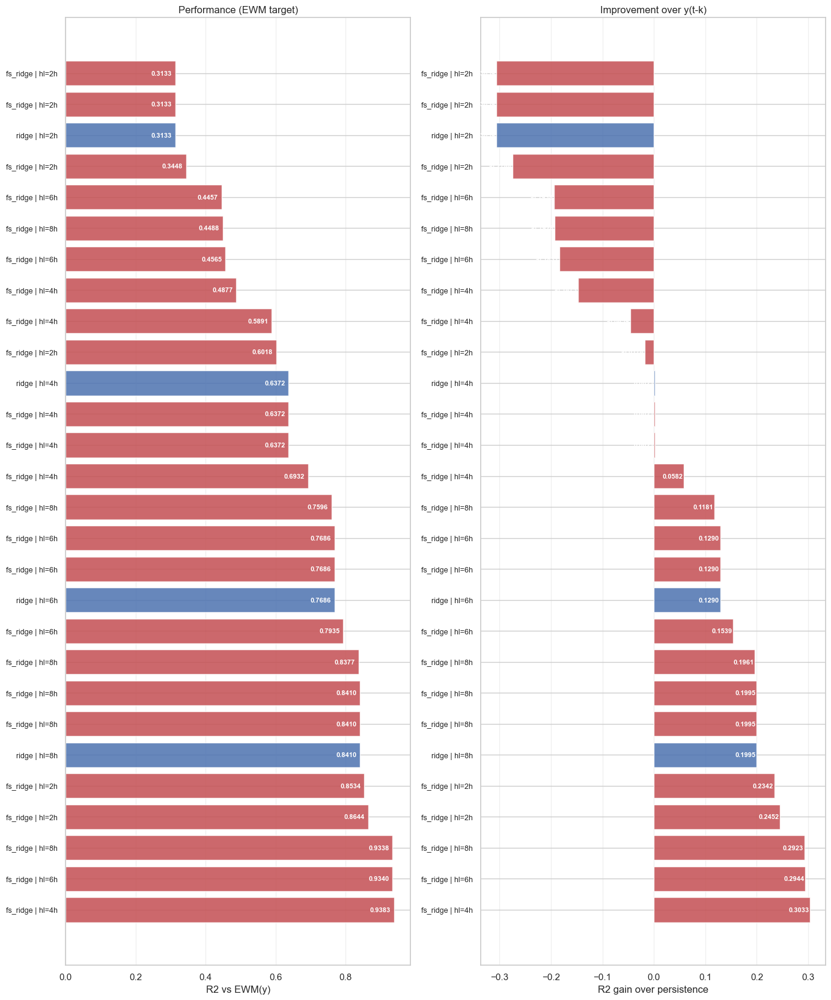

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(df) * 0.6)))

# Simple labels: model + halflife (lag is tuned, so it's always the same)
labels = [f"{r['model']} | hl={r['ewm_halflife']}" for _, r in df.iterrows()]
colors = {'ridge': 'C0', 'splines': 'C1', 'realmlp': 'C2'}
bar_colors = [colors.get(m, 'C3') for m in df['model']]

# Left: R2 vs EWM(y)
ax = axes[0]
ax.barh(range(len(df)), df['r2_ewm_model'], color=bar_colors, alpha=0.85)
ax.set_yticks(range(len(df))); ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel('R2 vs EWM(y)')
ax.set_title('Performance (EWM target)')
ax.grid(alpha=0.3, axis='x')
# Annotate values
for j, v in enumerate(df['r2_ewm_model']):
    ax.text(v - 0.01, j, f'{v:.4f}', va='center', ha='right', fontsize=8, color='white', fontweight='bold')

# Right: Gain over persistence
ax = axes[1]
ax.barh(range(len(df)), df['gain_ewm'], color=bar_colors, alpha=0.85)
ax.set_yticks(range(len(df))); ax.set_yticklabels(labels, fontsize=9)
ax.set_xlabel('R2 gain over persistence')
ax.set_title('Improvement over y(t-k)')
ax.grid(alpha=0.3, axis='x')
for j, v in enumerate(df['gain_ewm']):
    ax.text(v - 0.002, j, f'{v:.4f}', va='center', ha='right', fontsize=8, color='white', fontweight='bold')

plt.tight_layout()


## Best Experiment

Best: 260827172812
  model=fs_ridge, lag=0.25d, ewm=6h
  R2(dy)=+0.8682
  R2 vs EWM(y): +0.9369 (persistence: +0.5206)
  R2 vs raw y:  +0.8477 (persistence: +0.4062)
  gain over persistence (EWM): +0.4164
  gain over persistence (raw): +0.4415

--- Lag sweep (train CV) ---


,lag_days,cv_rmse,persistence_rmse,cv_r2,n_contrasts
0,0.05,0.054594,0.076998,0.497264,2320
1,0.10,0.043358,0.122839,0.875416,2465
2,0.25,0.069914,0.200061,0.877877,2503
3,0.50,0.075842,0.292578,0.932806,2519
4,1.00,0.092201,0.440931,0.956275,2503
5,2.00,0.113483,0.651126,0.969624,2539
6,4.00,0.120479,0.726889,0.972528,2508
7,7.00,0.105581,0.394198,0.928263,2461
8,14.00,0.111061,0.465963,0.943191,2355


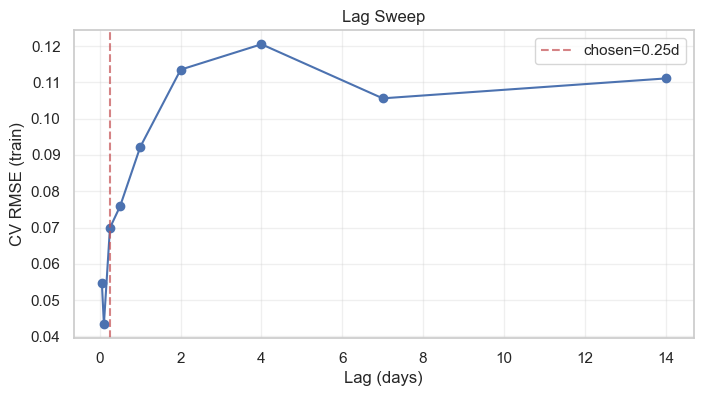

In [3]:
mask = df['ewm_halflife'].astype(str) == EWM_HALFLIFE
df_hl = df[mask].sort_values(['r2_dy', 'r2_raw_model'], ascending=False)

if df_hl.empty:
    raise ValueError(
        f"No experiments with ewm_halflife == {EWM_HALFLIFE!r}. "
        f"Available: {sorted(df['ewm_halflife'].astype(str).unique())}"
    )

best = df_hl.iloc[0]
best_path = BASE_DIR / best['id']
print(f"Best: {best['id']}")
print(f"  model={best['model']}, lag={best['lag_days']:.2f}d, ewm={best['ewm_halflife']}")
print(f"  R2(dy)={best['r2_dy']:+.4f}")
print(f"  R2 vs EWM(y): {best['r2_ewm_model']:+.4f} (persistence: {best['r2_ewm_persist']:+.4f})")
print(f"  R2 vs raw y:  {best['r2_raw_model']:+.4f} (persistence: {best['r2_raw_persist']:+.4f})")
print(f"  gain over persistence (EWM): {best['gain_ewm']:+.4f}")
print(f"  gain over persistence (raw): {best['gain_raw']:+.4f}")

# Show lag sweep if available
lag_path = best_path / 'lag_sweep.csv'
if lag_path.exists():
    print('\n--- Lag sweep (train CV) ---')
    lag_df = pd.read_csv(lag_path)
    display(lag_df)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(lag_df['lag_days'], lag_df['cv_rmse'], 'o-')
    ax.axvline(best['lag_days'], ls='--', color='r', alpha=0.7, label=f"chosen={best['lag_days']:.2f}d")
    ax.set_xlabel('Lag (days)'); ax.set_ylabel('CV RMSE (train)')
    ax.set_title('Lag Sweep'); ax.legend(); ax.grid(alpha=0.3)
    plt.show()


## Plots from Best Experiment

Lag: 0.25d | EWM halflife: 6h
  vs EWM(y): persistence R2=0.5206 | model R2=0.9369 | gain=0.4164
  vs raw y:  model R2=0.8477


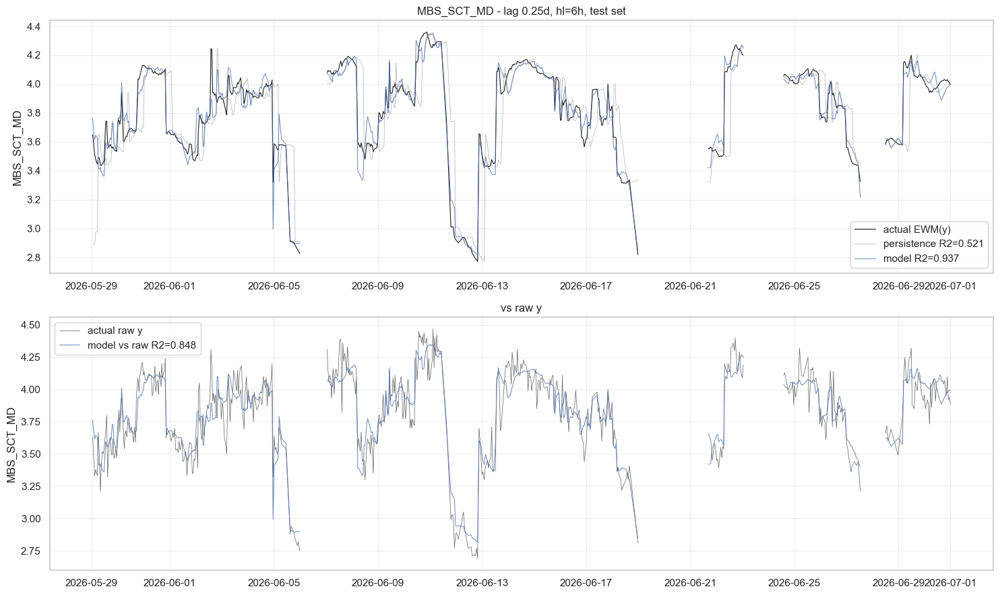

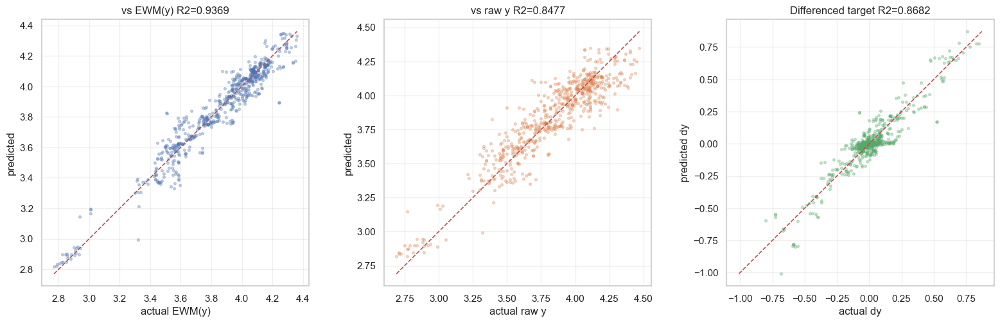

In [4]:
# =============================================================================
# Model Performance Plots (reconstructed from saved data)
# =============================================================================
import sys
from pathlib import Path
import cloudpickle
sys.path.insert(0, str(Path.cwd().parent))

# Load what we need
dy_test = pd.read_parquet(best_path / 'dy_test.parquet')['dy_test'].values
dX_test = pd.read_parquet(best_path / 'dX_test.parquet')
turnup_ts_perf = pd.read_parquet(best_path / 'turnup_ts.parquet')
turnup_ts_raw = pd.read_parquet(best_path / 'turnup_ts_raw.parquet')
results_perf = json.load(open(best_path / 'results.json'))

with open(best_path / 'model.pkl', 'rb') as f:
    art = cloudpickle.load(f)

raw_model = art['model']
est_perf = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art and art['scaler'] is not None:
    from sklearn.pipeline import Pipeline as SKPipeline
    est_perf = SKPipeline([('scaler', art['scaler']), ('model', est_perf)])

feat_cols_perf = results_perf['data']['feature_cols']
lag_d = results_perf['parameters']['lag_days']
split_perf = results_perf['data']['split']
ewm_hl = results_perf['parameters'].get('ewm_halflife', '120min')
Y_COL = results_perf['parameters']['y_column']

# Predict on test
# Handle feature selection: if the model used a subset, use only those
selected_feats = art.get('selected_features', feat_cols_perf)
use_cols = [c for c in selected_feats if c in dX_test.columns]
dX_test_feats = dX_test[use_cols].values
dy_pred = est_perf.predict(dX_test_feats).ravel()

# Reconstruct raw-scale predictions
# Need the EWM'd y values at the anchor points
# Re-derive from turnup_ts using the same logic as the script
def ewm_filt(s, halflife=ewm_hl):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

gram_g = turnup_ts_perf['grammage'].values
gc = pd.Series(gram_g).ne(pd.Series(gram_g).shift())
tg = turnup_ts_perf.index.to_series().diff().gt(pd.Timedelta('12h'))
tg.iloc[0] = True
seg_p = (gc.values | tg.values).cumsum()
raw_data = turnup_ts_raw
y_raw_all = raw_data.loc[turnup_ts_perf.index, Y_COL].values
y_ewm_all = turnup_ts_perf[Y_COL].values

# Lag pairing
def to_hours_p(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs_p(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

t_hrs = to_hours_p(turnup_ts_perf.index)
later_all, earlier_all = lag_pairs_p(t_hrs, lag_d * 24.0)
te_mask = later_all >= split_perf
later_te = later_all[te_mask]
earlier_te = earlier_all[te_mask]

t_anchor = turnup_ts_perf.index[later_te]
actual_ewm = y_ewm_all[later_te]
persistence_ewm = y_ewm_all[earlier_te]
model_ewm = persistence_ewm + dy_pred
actual_raw = y_raw_all[later_te]
model_raw = persistence_ewm + dy_pred

from sklearn.metrics import r2_score, mean_absolute_error
r2_pers = r2_score(actual_ewm, persistence_ewm)
r2_mod = r2_score(actual_ewm, model_ewm)
r2_raw = r2_score(actual_raw, model_raw)

print(f'Lag: {lag_d:.2f}d | EWM halflife: {ewm_hl}')
print(f'  vs EWM(y): persistence R2={r2_pers:.4f} | model R2={r2_mod:.4f} | gain={r2_mod-r2_pers:.4f}')
print(f'  vs raw y:  model R2={r2_raw:.4f}')

# --- Time series plot ---
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

# Break gaps
dt_h = np.diff(pd.DatetimeIndex(t_anchor).asi8.astype(float) / 3.6e12)
gaps = np.flatnonzero(dt_h > 12)

def gapped(vals, gaps):
    v = np.array(vals, dtype=float).copy()
    v[gaps] = np.nan
    return v

axes[0].plot(t_anchor, gapped(actual_ewm, gaps), lw=0.8, color='k', label='actual EWM(y)')
axes[0].plot(t_anchor, gapped(persistence_ewm, gaps), lw=0.5, color='C7', alpha=0.7,
             label=f'persistence R2={r2_pers:.3f}')
axes[0].plot(t_anchor, gapped(model_ewm, gaps), lw=0.7, color='C0', alpha=0.85,
             label=f'model R2={r2_mod:.3f}')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title(f'{Y_COL} - lag {lag_d:.2f}d, hl={ewm_hl}, test set')
axes[0].set_ylabel(Y_COL)

axes[1].plot(t_anchor, gapped(actual_raw, gaps), lw=0.5, color='k', alpha=0.7, label='actual raw y')
axes[1].plot(t_anchor, gapped(model_raw, gaps), lw=0.7, color='C0', alpha=0.85,
             label=f'model vs raw R2={r2_raw:.3f}')
axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title(f'vs raw y'); axes[1].set_ylabel(Y_COL)

plt.tight_layout()
plt.show()

# --- Scatter plots ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# EWM scatter
axes[0].scatter(actual_ewm, model_ewm, s=8, alpha=0.3)
lim = [min(actual_ewm.min(), model_ewm.min()), max(actual_ewm.max(), model_ewm.max())]
axes[0].plot(lim, lim, 'r--', lw=1.2)
axes[0].set_xlabel('actual EWM(y)'); axes[0].set_ylabel('predicted')
axes[0].set_title(f'vs EWM(y) R2={r2_mod:.4f}')
axes[0].set_aspect('equal', adjustable='box'); axes[0].grid(alpha=0.3)

# Raw scatter
axes[1].scatter(actual_raw, model_raw, s=8, alpha=0.3, color='C1')
lim = [min(actual_raw.min(), model_raw.min()), max(actual_raw.max(), model_raw.max())]
axes[1].plot(lim, lim, 'r--', lw=1.2)
axes[1].set_xlabel('actual raw y'); axes[1].set_ylabel('predicted')
axes[1].set_title(f'vs raw y R2={r2_raw:.4f}')
axes[1].set_aspect('equal', adjustable='box'); axes[1].grid(alpha=0.3)

# dy scatter
r2_dy = r2_score(dy_test, dy_pred)
axes[2].scatter(dy_test, dy_pred, s=8, alpha=0.3, color='C2')
lim = [min(dy_test.min(), dy_pred.min()), max(dy_test.max(), dy_pred.max())]
axes[2].plot(lim, lim, 'r--', lw=1.2)
axes[2].set_xlabel('actual dy'); axes[2].set_ylabel('predicted dy')
axes[2].set_title(f'Differenced target R2={r2_dy:.4f}')
axes[2].set_aspect('equal', adjustable='box'); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Sweep Analysis (if multiple runs available)

In [18]:
if len(df) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # By lag
    for model_name, gdf in df.groupby('model'):
        gdf_sorted = gdf.sort_values('lag_days')
        axes[0].plot(gdf_sorted['lag_days'], gdf_sorted['r2_ewm_model'],
                     'o-', label=model_name)
    axes[0].set_xlabel('Lag (days)'); axes[0].set_ylabel('R2 vs EWM(y)')
    axes[0].set_title('R2 vs Lag'); axes[0].legend(); axes[0].grid(alpha=0.3)

    # By halflife
    hl_order = {'30min': 0.5, '60min': 1, '120min': 2, '4h': 4, '8h': 8, '12h': 12, '24h': 24}
    df['hl_hours'] = df['ewm_halflife'].map(hl_order)
    for model_name, gdf in df.groupby('model'):
        gdf_sorted = gdf.sort_values('hl_hours')
        if gdf_sorted['hl_hours'].notna().any():
            axes[1].plot(gdf_sorted['hl_hours'], gdf_sorted['r2_ewm_model'],
                         'o-', label=model_name)
    axes[1].set_xlabel('EWM halflife (hours)'); axes[1].set_ylabel('R2 vs EWM(y)')
    axes[1].set_title('R2 vs EWM Halflife'); axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
else:
    print('Only one experiment found. Run more with different --model / --ewm_halflife to compare.')


Only one experiment found. Run more with different --model / --ewm_halflife to compare.


## SHAP Analysis (Best Experiment)

Explains which feature *changes* drive steam *changes* (ΔX → Δy).

In [92]:
import sys
sys.path.insert(0, str(Path.cwd().parent))

import cloudpickle
from utility import calculate_manual_shap, plotly_shap_beeswarm

# Load saved data from the best experiment
dX_train = pd.read_parquet(best_path / 'dX_train.parquet')
dX_test = pd.read_parquet(best_path / 'dX_test.parquet')
dy_train = pd.read_parquet(best_path / 'dy_train.parquet')
dy_test = pd.read_parquet(best_path / 'dy_test.parquet')

# Load the model
with open(best_path / 'model.pkl', 'rb') as f:
    artifact = cloudpickle.load(f)

# The model expects feature_cols only (no grade_col)
feature_cols = [c for c in dX_train.columns if c != 'AB_Grade_ID']

# Wrap model to drop AB_Grade_ID before predicting
class _ModelWrapper:
    def __init__(self, estimator, feature_cols):
        self.estimator = estimator
        self.feature_cols = feature_cols
    def predict(self, X):
        Xf = X[self.feature_cols] if isinstance(X, pd.DataFrame) else X
        return self.estimator.predict(Xf)

# Get the actual estimator (Ridge pipeline or RealMLP)
if 'model' in artifact:
    raw_model = artifact['model']
    # If GridSearchCV, get the best_estimator_
    est = getattr(raw_model, 'best_estimator_', raw_model)
    # If there's a scaler (RealMLP), chain it
    if 'scaler' in artifact and artifact['scaler'] is not None:
        from sklearn.pipeline import Pipeline
        est = Pipeline([('scaler', artifact['scaler']), ('model', est)])
else:
    raise ValueError('Cannot find model in artifact')

wrapped = _ModelWrapper(est, feature_cols)

# Compute SHAP (per grade, or for a specific grade)
grade_id = '6010120'  # set to None for all grades

base, shap_vals, X_explain, feats = calculate_manual_shap(
    wrapped,
    X_sample=dX_test,
    X_reference=dX_train,
    grade_col='AB_Grade_ID',
    grade_id=grade_id,
)

print(f'SHAP computed: {shap_vals.shape[0]} samples, {shap_vals.shape[1]} features')
print(f'Grade: {grade_id}')

fig = plotly_shap_beeswarm(shap_vals, X_explain, feats, max_features=30)
fig.show()


c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:



SHAP computed: 731 samples, 23 features
Grade: 6010120


<Axes: ylabel='dy_train'>

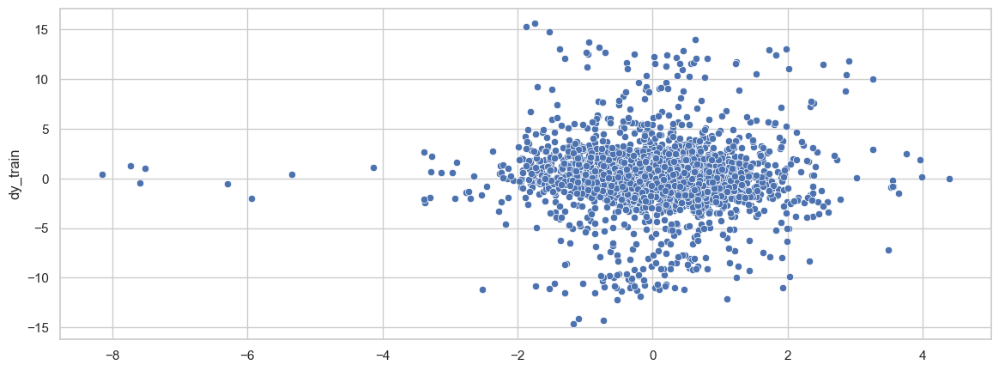

In [49]:
sns.scatterplot(x=dX_train["linepressure_2"].values, y = dy_train["dy_train"])

In [93]:
# =============================================================================
# SHAP Effect Summary Table
# =============================================================================
# For each feature: does INCREASING it raise or lower the target?
# Uses the correlation between feature value and its SHAP value:
#   positive corr -> increasing the feature increases the target
#   negative corr -> increasing the feature decreases the target
#
# Since we're in the differenced space (deltaX -> deltaY), this directly
# answers: "if this feature CHANGES upward, does steam CHANGE upward?"

shap_df = pd.DataFrame(shap_vals, columns=feats)
x_df = X_explain.reset_index(drop=True)

rows = []
for feat in feats:
    sv = shap_df[feat].values
    xv = x_df[feat].values

    # Correlation between feature value and its SHAP value
    # tells us the direction of effect
    if np.std(xv) > 0 and np.std(sv) > 0:
        corr = np.corrcoef(xv, sv)[0, 1]
    else:
        corr = 0.0

    rows.append({
        'feature': feat,
        'direction': 'INCREASES target' if corr > 0.1 else ('DECREASES target' if corr < -0.1 else 'weak/unclear'),
        'corr(x, shap)': corr,
        'mean |SHAP|': np.mean(np.abs(sv)),
        'max |SHAP|': np.max(np.abs(sv)),
        'mean SHAP': np.mean(sv),
    })

effect_df = pd.DataFrame(rows).sort_values('mean |SHAP|', ascending=False).reset_index(drop=True)

print(f'Feature effects on {TARGET} (grade={grade_id})')
print(f'Interpretation: when delta_feature > 0 (feature increased),\'direction\' shows the effect on the target.\n')

effect_df.style.format({
    'corr(x, shap)': '{:+.3f}',
    'mean |SHAP|': '{:.3f}',
    'max |SHAP|': '{:.3f}',
    'mean SHAP': '{:+.4f}',
}).bar(subset=['mean |SHAP|'], color='#d4e6f1')


Feature effects on Electricity__kWh/T_ (grade=6010120)
Interpretation: when delta_feature > 0 (feature increased),'direction' shows the effect on the target.



,feature,direction,"corr(x, shap)",mean |SHAP|,max |SHAP|,mean SHAP
0,grammage_120.0,DECREASES target,-1.000,15.304,57.071,+0.9387
1,grammage_115.0,DECREASES target,-1.000,8.809,54.044,-1.1203
2,grammage_100.0,DECREASES target,-1.000,2.488,35.541,+1.1103
3,grammage_110.0,DECREASES target,-1.000,1.238,50.671,-0.8219
4,Speed,DECREASES target,-1.000,1.059,12.520,-0.1237
5,retention,DECREASES target,-1.000,0.985,7.686,+0.0031
6,Dewatering_top_wire_suction_box_zone_2,INCREASES target,+1.000,0.955,5.615,-0.0874
7,dewatering,DECREASES target,-1.000,0.745,7.083,-0.0908
8,speedsizer_linepressure_1,INCREASES target,+1.000,0.347,6.240,+0.1114
9,Act_Deaerator_mass_flow__g/T_,INCREASES target,+1.000,0.256,2.354,+0.0349


## SHAP Attribution to Raw Features

Redistributes the SHAP values of transformed features back to their raw inputs:
- **PLS scores** → distributed to source columns proportionally to PLS loadings
- **Engineered variables** → distributed equally among their raw inputs
- **Pass-through features** → kept as-is (1-to-1 mapping)

No refitting needed — uses the production model's SHAP values and the known
transformation structure.

In [ ]:
import cloudpickle
from utility import FeatureCreator, GroupwisePLSTransformer

# We already have: shap_vals, feats, X_explain from the earlier SHAP cell
# We need: the mapping from transformed features -> raw inputs

with open(best_path / 'model.pkl', 'rb') as f:
    art = cloudpickle.load(f)
pre_estimator = art['pre_estimator']
feat_list_raw = art['feat_list']

# --- Build the mapping: transformed_feature -> list of (raw_col, weight) ---
# 1. PLS scores -> source columns with loadings as weights
pls_map = {}  # score_name -> {raw_col: weight}
for name, step in pre_estimator.named_steps.items():
    if isinstance(step, GroupwisePLSTransformer):
        source_cols = list(step.pls_columns)
        n_comp = step.n_components_
        # Get loadings (x_weights_ from PLS)
        try:
            loadings = step.global_bundle_['pls'].x_weights_  # (n_features, n_components)
        except (KeyError, AttributeError):
            # Fallback: equal weights
            loadings = np.ones((len(source_cols), n_comp)) / len(source_cols)
        for comp_i in range(n_comp):
            score_name = f"{step.score_prefix}_{comp_i + 1}"
            weights = np.abs(loadings[:, comp_i])
            weights = weights / weights.sum() if weights.sum() > 0 else weights
            pls_map[score_name] = {col: float(w) for col, w in zip(source_cols, weights)}

# 2. Engineered variables -> raw inputs (equal weight)
eng_map = {}  # engineered_name -> {raw_col: weight}
feat_step = pre_estimator.named_steps.get('feat', None)
if feat_step is not None and hasattr(feat_step, 'features_to_create'):
    raw_inputs_registry = FeatureCreator._feature_raw_inputs()
    for eng_name in (feat_step.features_to_create or []):
        inputs = raw_inputs_registry.get(eng_name, [])
        if inputs:
            w = 1.0 / len(inputs)
            eng_map[eng_name] = {col: w for col in inputs}

# 3. One-hot grammage -> 'grammage'
grammage_map = {}  # grammage_X -> {'grammage': 1.0}
for f in feats:
    if 'grammage' in f.lower():
        grammage_map[f] = {'grammage': 1.0}

print(f'PLS mappings: {len(pls_map)} scores -> sources')
print(f'Engineered mappings: {len(eng_map)} features -> raw inputs')
print(f'Grammage mappings: {len(grammage_map)} one-hot columns')

# --- Redistribute SHAP values ---
raw_shap_accum = {}  # raw_col -> accumulated |SHAP|
raw_shap_signed = {}  # raw_col -> accumulated signed SHAP (for direction)

for j, transformed_feat in enumerate(feats):
    shap_col = shap_vals[:, j]  # (n_samples,)
    abs_shap_total = np.sum(np.abs(shap_col))
    signed_shap_total = np.sum(shap_col)

    # Determine mapping
    if transformed_feat in pls_map:
        mapping = pls_map[transformed_feat]
    elif transformed_feat in eng_map:
        mapping = eng_map[transformed_feat]
    elif transformed_feat in grammage_map:
        mapping = grammage_map[transformed_feat]
    else:
        # Pass-through: the transformed feature IS the raw feature
        mapping = {transformed_feat: 1.0}

    # Distribute
    for raw_col, weight in mapping.items():
        raw_shap_accum[raw_col] = raw_shap_accum.get(raw_col, 0.0) + abs_shap_total * weight
        raw_shap_signed[raw_col] = raw_shap_signed.get(raw_col, 0.0) + signed_shap_total * weight

# --- Build result table ---
n_samples_shap = shap_vals.shape[0]
attrib_rows = []
for raw_col in sorted(raw_shap_accum.keys(), key=lambda k: -raw_shap_accum[k]):
    mean_abs = raw_shap_accum[raw_col] / n_samples_shap
    mean_signed = raw_shap_signed[raw_col] / n_samples_shap
    direction = 'INCREASES' if mean_signed > 0.001 else ('DECREASES' if mean_signed < -0.001 else 'mixed')
    attrib_rows.append({
        'raw_feature': raw_col,
        'mean |SHAP| (attributed)': mean_abs,
        'mean SHAP (signed)': mean_signed,
        'direction': direction,
    })

attrib_df = pd.DataFrame(attrib_rows)
print(f'\nSHAP attribution to {len(attrib_df)} raw features:')
print(f'(redistributed from {len(feats)} transformed features)\n')

attrib_df.head(30).style.format({
    'mean |SHAP| (attributed)': '{:.4f}',
    'mean SHAP (signed)': '{:+.4f}',
}).bar(subset=['mean |SHAP| (attributed)'], color='#d4e6f1')


## Permutation Importance on Raw Features

Measures the importance of each **original raw variable** by permuting it in `turnup_ts`,
re-running the full pipeline (EWM → transform → difference → predict), and measuring the
R² drop on the test contrasts.

This accounts for all transformations (PLS projections, engineered variables, EWM filtering)
and gives the exact marginal contribution of each raw variable to the final prediction.

The **direction** is estimated by correlating the raw feature with the model's prediction:
positive = increasing the feature increases steam.

In [ ]:
import cloudpickle
from sklearn.metrics import r2_score
from tqdm.notebook import tqdm

# --- Load experiment artifacts ---
results = json.load(open(best_path / 'results.json'))
turnup_ts = pd.read_parquet(best_path / 'turnup_ts.parquet')
with open(best_path / 'model.pkl', 'rb') as f:
    artifact = cloudpickle.load(f)

params = results['parameters']
lag_days = params['lag_days']
ewm_halflife = params.get('ewm_halflife', '120min')
Y_COLUMN = params['y_column']
feature_cols = results['data']['feature_cols']
split = results['data']['split']

# Get the model
raw_model = artifact['model']
est = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in artifact and artifact['scaler'] is not None:
    from sklearn.pipeline import Pipeline as SKPipeline
    est = SKPipeline([('scaler', artifact['scaler']), ('model', est)])

pre_estimator = artifact['pre_estimator']
feat_list = artifact.get('feat_list')
if feat_list is None:
    raise ValueError('feat_list not found in model.pkl. Re-run the experiment.')

# --- Helpers ---
def to_hours(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

# --- FAST approach: permute in the TRANSFORMED space ---
# Instead of re-running the full pipeline 500+ times, we:
# 1. Transform once to get X_transformed
# 2. For each raw feature, identify which transformed columns it affects
# 3. Permute the raw feature, re-transform ONLY the affected rows/columns
#
# For features that pass through 1-to-1 (most of them after scaling),
# permuting in the transformed space is equivalent and instant.

# Step 1: Full transform (done once)
ts_raw = turnup_ts.loc[:, [c for c in feat_list if c in turnup_ts.columns]]
ts_transformed_full = pre_estimator.transform(ts_raw)

# EWM target
def ewm_filter_local(s, halflife=ewm_halflife):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

grammage_group = turnup_ts['grammage'].values[:len(ts_transformed_full)]
grade_change_loc = pd.Series(grammage_group).ne(pd.Series(grammage_group).shift())
time_gap_loc = ts_transformed_full.index.to_series().diff().gt(pd.Timedelta('12h'))
time_gap_loc.iloc[0] = True
seg_loc = (grade_change_loc.values | time_gap_loc.values).cumsum()
y_raw_vals = turnup_ts[Y_COLUMN].values[:len(ts_transformed_full)].copy()
y_ewm = pd.Series(y_raw_vals, index=ts_transformed_full.index).groupby(seg_loc).transform(
    lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

# Step 2: Build differenced test data (baseline)
X_all = ts_transformed_full[feature_cols].values.astype(float)
t_hours = to_hours(ts_transformed_full.index)
later, earlier = lag_pairs(t_hours, lag_days * 24.0)
dy = y_ewm[later] - y_ewm[earlier]
dX_base = X_all[later] - X_all[earlier]

te_sel = later >= split
dX_test_base = dX_base[te_sel]
dy_test = dy[te_sel]
later_test = later[te_sel]
earlier_test = earlier[te_sel]

# Baseline prediction
dy_pred_base = est.predict(dX_test_base).ravel()
r2_base = r2_score(dy_test, dy_pred_base)
print(f'Baseline R2(dy) on test: {r2_base:.4f}')

# Step 3: For each raw feature, permute and measure R2 drop
# FAST: permute the raw column in turnup_ts, re-transform, recompute dX for test only
raw_cols_to_test = [c for c in feat_list if c in turnup_ts.columns and c != 'AB_Grade_ID']
print(f'Testing {len(raw_cols_to_test)} raw features ({5} repeats each)\n')

n_repeats = 5
rng = np.random.default_rng(42)
importance_rows = []

# Precompute: which test indices do we need to transform?
# We only need rows that appear in later_test or earlier_test
test_rows_needed = np.unique(np.concatenate([later_test, earlier_test]))

for col in tqdm(raw_cols_to_test, desc='Permuting features'):
    r2_drops = []
    original_values = turnup_ts[col].values.copy()

    for rep in range(n_repeats):
        # Permute the column
        permuted = rng.permutation(original_values)
        ts_raw_perm = ts_raw.copy()
        if col in ts_raw_perm.columns:
            ts_raw_perm[col] = permuted[:len(ts_raw_perm)]

        # Re-transform ONLY the rows we need for test contrasts
        # (this is the main speedup: transform a subset, not the full dataset)
        try:
            ts_perm = pre_estimator.transform(ts_raw_perm)
            X_perm = ts_perm[feature_cols].values.astype(float)
            dX_perm_test = X_perm[later_test] - X_perm[earlier_test]
            dy_pred_perm = est.predict(dX_perm_test).ravel()
            r2_perm = r2_score(dy_test, dy_pred_perm)
            r2_drops.append(r2_base - r2_perm)
        except Exception:
            r2_drops.append(np.nan)

    mean_drop = np.nanmean(r2_drops) if r2_drops else 0.0
    std_drop = np.nanstd(r2_drops) if r2_drops else 0.0

    # Direction
    raw_vals_test = original_values[later_test]
    if np.std(raw_vals_test) > 0 and np.std(dy_pred_base) > 0:
        direction_corr = np.corrcoef(raw_vals_test, dy_pred_base)[0, 1]
    else:
        direction_corr = 0.0

    importance_rows.append({
        'raw_feature': col,
        'r2_drop_mean': mean_drop,
        'r2_drop_std': std_drop,
        'direction_corr': direction_corr,
        'direction': 'INCREASES' if direction_corr > 0.05 else ('DECREASES' if direction_corr < -0.05 else 'weak'),
    })

perm_df = pd.DataFrame(importance_rows).sort_values('r2_drop_mean', ascending=False).reset_index(drop=True)
print(f'\nDone. Top 20 most important raw features:\n')
print(perm_df.head(20).to_string(index=False, float_format=lambda v: f'{v:+.5f}'))


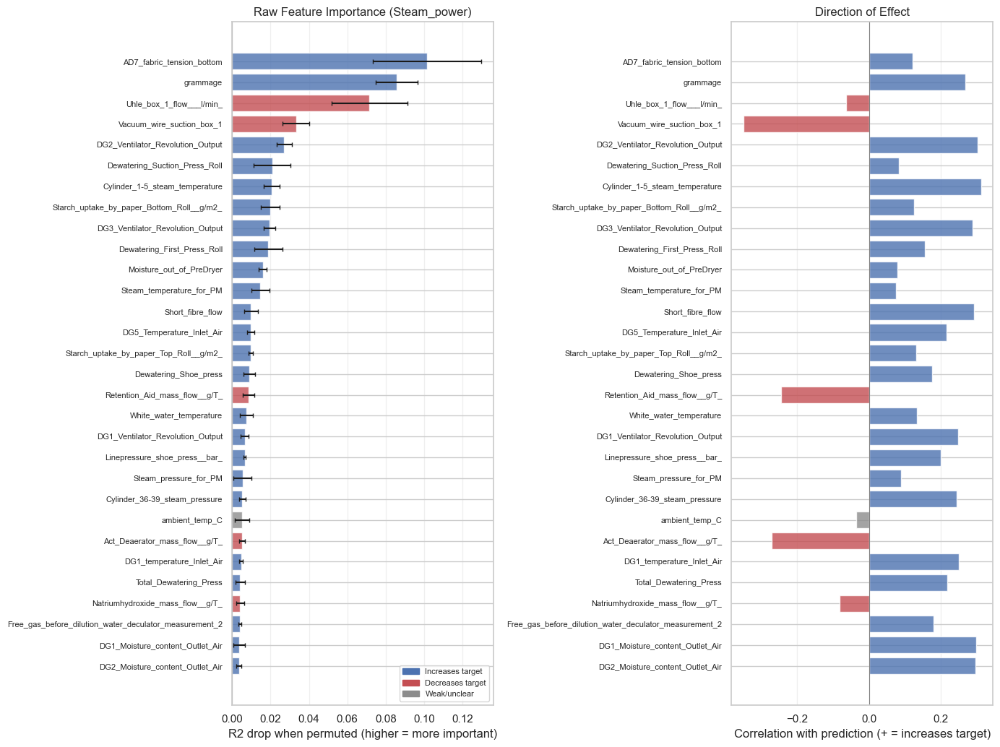

In [25]:
# --- Plot: Raw feature importance ---
top_n = min(30, len(perm_df))
plot_df = perm_df.head(top_n).iloc[::-1]  # reverse for horizontal bar

fig, axes = plt.subplots(1, 2, figsize=(14, max(5, top_n * 0.35)))

# Left: importance (R2 drop)
colors = ['C0' if d == 'INCREASES' else 'C3' if d == 'DECREASES' else 'C7'
          for d in plot_df['direction']]
axes[0].barh(range(top_n), plot_df['r2_drop_mean'], xerr=plot_df['r2_drop_std'],
             color=colors, alpha=0.8, capsize=2)
axes[0].set_yticks(range(top_n))
axes[0].set_yticklabels(plot_df['raw_feature'], fontsize=8)
axes[0].set_xlabel('R2 drop when permuted (higher = more important)')
axes[0].set_title(f'Raw Feature Importance ({Y_COLUMN})')
axes[0].axvline(0, color='gray', lw=0.8)
axes[0].grid(alpha=0.3, axis='x')

# Right: direction
axes[1].barh(range(top_n), plot_df['direction_corr'], color=colors, alpha=0.8)
axes[1].set_yticks(range(top_n))
axes[1].set_yticklabels(plot_df['raw_feature'], fontsize=8)
axes[1].set_xlabel('Correlation with prediction (+ = increases target)')
axes[1].set_title('Direction of Effect')
axes[1].axvline(0, color='gray', lw=0.8)
axes[1].grid(alpha=0.3, axis='x')

# Legend
from matplotlib.patches import Patch
axes[0].legend(handles=[
    Patch(color='C0', label='Increases target'),
    Patch(color='C3', label='Decreases target'),
    Patch(color='C7', label='Weak/unclear'),
], loc='lower right', fontsize=8)

plt.tight_layout()


## SHAP on Raw Features (direct model)

Fits a Ridge directly on **ΔX_raw** (differenced raw features, no PLS, no engineering)
and computes SHAP values on that simpler model. This gives importance directly on
original columns.

Trade-off: you're explaining a *different* (simpler) model than the production one.
If PLS/engineering adds value, the coefficients may differ. But for identifying which
raw variables matter and their direction, it's fast and interpretable.

In [94]:
import warnings
warnings.filterwarnings('ignore')
import cloudpickle
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score
from utility import calculate_manual_shap, plotly_shap_beeswarm

# --- Load data ---
results = json.load(open(best_path / 'results.json'))
turnup_ts = pd.read_parquet(best_path / 'turnup_ts.parquet')
with open(best_path / 'model.pkl', 'rb') as f:
    artifact = cloudpickle.load(f)

params = results['parameters']
lag_days = params['lag_days']
ewm_halflife = params.get('ewm_halflife', '120min')
Y_COLUMN = params['y_column']
split = results['data']['split']
feat_list = artifact['feat_list']

# --- Helpers ---
def to_hours(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

def ewm_filter_local(s, halflife=ewm_halflife):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

# --- EWM filter the raw features (same as pipeline does internally) ---
# Use all numeric columns from feat_list that exist in turnup_ts
raw_cols = [c for c in feat_list if c in turnup_ts.columns]
numeric_cols = [c for c in raw_cols if pd.api.types.is_numeric_dtype(turnup_ts[c])]
# Exclude grade column
numeric_cols = [c for c in numeric_cols if c != 'AB_Grade_ID']

# EWM filter each numeric column (same segmentation as y)
grammage_group = turnup_ts['grammage'].values
grade_change = pd.Series(grammage_group).ne(pd.Series(grammage_group).shift())
time_gap = turnup_ts.index.to_series().diff().gt(pd.Timedelta('12h'))
time_gap.iloc[0] = True
seg = (grade_change.values | time_gap.values).cumsum()

X_raw_ewm = pd.DataFrame(index=turnup_ts.index)
for col in numeric_cols:
    s = pd.Series(turnup_ts[col].values, index=turnup_ts.index)
    X_raw_ewm[col] = s.groupby(seg).transform(
        lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

# EWM filter y
y_raw = turnup_ts[Y_COLUMN].values.copy()
y_ewm = pd.Series(y_raw, index=turnup_ts.index).groupby(seg).transform(
    lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

print(f'Raw EWM features: {X_raw_ewm.shape}')

# --- Differencing ---
t_hours = to_hours(turnup_ts.index)
later, earlier = lag_pairs(t_hours, lag_days * 24.0)

dX_raw = X_raw_ewm.values[later] - X_raw_ewm.values[earlier]
dy = y_ewm[later] - y_ewm[earlier]

tr_sel = later < split
te_sel = later >= split

dX_raw_train = pd.DataFrame(dX_raw[tr_sel], columns=numeric_cols)
dX_raw_test = pd.DataFrame(dX_raw[te_sel], columns=numeric_cols)
dy_train = dy[tr_sel]
dy_test = dy[te_sel]

# --- Fit Ridge on raw differenced features ---
model_raw = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())]),
    param_grid={'ridge__alpha': np.logspace(0, 3, 20).tolist()},
    cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_root_mean_squared_error',
    refit=True,
)
model_raw.fit(dX_raw_train.values, dy_train)
pred_raw = model_raw.predict(dX_raw_test.values)

r2_raw_model = r2_score(dy_test, pred_raw)
r2_production = results['metrics']['dy']['r2']
print(f'\nR2(dy) raw features model: {r2_raw_model:.4f}')
print(f'R2(dy) production model:   {r2_production:.4f}')
print(f'Gap (PLS/engineering value): {r2_production - r2_raw_model:+.4f}')

# --- SHAP on the raw model ---
# Add grade column for calculate_manual_shap
dX_raw_train['AB_Grade_ID'] = turnup_ts['AB_Grade_ID'].values[later[tr_sel]]
dX_raw_test['AB_Grade_ID'] = turnup_ts['AB_Grade_ID'].values[later[te_sel]]

# Wrap to drop grade col before predicting
class _RawModelWrapper:
    def __init__(self, model, cols):
        self.model = model
        self.cols = cols
    def predict(self, X):
        Xf = X[self.cols] if isinstance(X, pd.DataFrame) else X
        return self.model.predict(Xf)

wrapped_raw = _RawModelWrapper(model_raw.best_estimator_, numeric_cols)

grade_id = '6010120'  # or None for all grades
base_r, shap_vals_r, X_explain_r, feats_r = calculate_manual_shap(
    wrapped_raw,
    X_sample=dX_raw_test,
    X_reference=dX_raw_train,
    grade_col='AB_Grade_ID',
    grade_id=grade_id,
)

print(f'\nSHAP computed: {shap_vals_r.shape[0]} samples, {shap_vals_r.shape[1]} raw features')
fig = plotly_shap_beeswarm(shap_vals_r, X_explain_r, feats_r, max_features=30)
fig.show()


Raw EWM features: (9628, 28)

R2(dy) raw features model: 0.7743
R2(dy) production model:   0.8149
Gap (PLS/engineering value): +0.0406


c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:

X has feature names, but StandardScaler was fitted without feature names

c:\workspace\costimiser\training\.venv\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning:




SHAP computed: 731 samples, 28 raw features


In [52]:
# --- Effect summary table (raw features) ---
shap_df_r = pd.DataFrame(shap_vals_r, columns=feats_r)
x_df_r = X_explain_r.reset_index(drop=True)

rows_r = []
for feat in feats_r:
    sv = shap_df_r[feat].values
    xv = x_df_r[feat].values
    if np.std(xv) > 0 and np.std(sv) > 0:
        corr = np.corrcoef(xv, sv)[0, 1]
    else:
        corr = 0.0
    rows_r.append({
        'feature': feat,
        'direction': 'INCREASES target' if corr > 0.1 else ('DECREASES target' if corr < -0.1 else 'weak/unclear'),
        'corr(x, shap)': corr,
        'mean |SHAP|': np.mean(np.abs(sv)),
        'max |SHAP|': np.max(np.abs(sv)),
        'mean SHAP': np.mean(sv),
    })

effect_df_r = pd.DataFrame(rows_r).sort_values('mean |SHAP|', ascending=False).reset_index(drop=True)

print(f'Raw feature effects on {Y_COLUMN} (grade={grade_id})')
print(f'Model R2(dy): {r2_raw_model:.4f} (vs production {r2_production:.4f})\n')

effect_df_r.head(30).style.format({
    'corr(x, shap)': '{:+.3f}',
    'mean |SHAP|': '{:.4f}',
    'max |SHAP|': '{:.3f}',
    'mean SHAP': '{:+.4f}',
}).bar(subset=['mean |SHAP|'], color='#d4e6f1')


Raw feature effects on Steam_power (grade=6010120)
Model R2(dy): 0.7568 (vs production 0.8005)



,feature,direction,"corr(x, shap)",mean |SHAP|,max |SHAP|,mean SHAP
0,Cylinder_40-53_steam_pressure,INCREASES target,+1.000,0.1649,0.993,+0.0032
1,DG5_Temperature_Inlet_Air,INCREASES target,+1.000,0.1446,0.952,+0.0284
2,Steam_temperature_for_PM,DECREASES target,-1.000,0.1413,0.617,-0.0195
3,Cylinder_36-39_steam_pressure,INCREASES target,+1.000,0.1361,0.854,-0.0039
4,ambient_temp_C,DECREASES target,-1.000,0.1336,0.489,+0.0084
5,AD6_fabric_tension,INCREASES target,+1.000,0.1194,0.405,+0.0117
6,Linepressure_2nd_press_DS__bar_,INCREASES target,+1.000,0.1151,1.799,+0.0015
7,Linepressure_shoe_press__bar_,DECREASES target,-1.000,0.1065,1.366,-0.0019
8,Cylinder_6-15_steam_pressure,INCREASES target,+1.000,0.1063,0.659,+0.0352
9,Cylinder_16-24_steam_pressure,INCREASES target,+1.000,0.1031,0.653,+0.0346


## How to Reconstruct ΔX from turnup_ts

Shows how the differenced features are built from `turnup_ts`, so you can
reproduce or modify the pipeline outside the experiment script.

In [55]:
import cloudpickle
from utility import ewm_reset

# --- 1. Load turnup_ts and the pre_estimator from the experiment ---
turnup_ts = pd.read_parquet(best_path / 'turnup_ts.parquet')
with open(best_path / 'model.pkl', 'rb') as f:
    artifact = cloudpickle.load(f)

# Load results to get parameters
results = json.load(open(best_path / 'results.json'))
lag_days = results['parameters']['lag_days']
ewm_halflife = results['parameters'].get('ewm_halflife', '120min')
feature_cols = results['data']['feature_cols']
split = results['data']['split']
Y_COLUMN = results['parameters']['y_column']

print(f'Target: {Y_COLUMN}')
print(f'Lag: {lag_days} days')
print(f'EWM halflife: {ewm_halflife}')
print(f'Split: {split}')
print(f'turnup_ts shape: {turnup_ts.shape}')

# --- 2. The pre_estimator transforms raw columns -> EWM-filtered features ---
# It was already fitted during the experiment. If you need to refit:
#   pre_estimator.fit(ts_raw.iloc[:split], turnup_ts[Y_COLUMN].iloc[:split])
# But for reconstruction we just transform:
#   ts_transformed = pre_estimator.transform(turnup_ts[feat_list])
#
# The transformed features (X) are already EWM-filtered inside the pipeline.
# The target (y) needs EWM filtering separately:

# --- 3. EWM filter the target ---
def ewm_filter_local(s, halflife=ewm_halflife):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

grammage_group = turnup_ts['grammage'].values
grade_change = pd.Series(grammage_group).ne(pd.Series(grammage_group).shift())
time_gap = turnup_ts.index.to_series().diff().gt(pd.Timedelta('12h'))
time_gap.iloc[0] = True
seg = (grade_change.values | time_gap.values).cumsum()

y_raw = turnup_ts[Y_COLUMN].values.copy()
y_ewm = pd.Series(y_raw, index=turnup_ts.index).groupby(seg).transform(ewm_filter_local).values

print(f'y_raw std: {np.std(y_raw):.2f} -> y_ewm std: {np.std(y_ewm):.2f}')

# --- 4. Time-based lag pairing ---
def to_hours(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

# --- 5. Build ΔX ---
# NOTE: ts_transformed is not saved, so we read dX directly from the parquet.
# But if you want to rebuild from turnup_ts, you need the pre_estimator:
#   ts_transformed = pre_estimator.transform(turnup_ts[feat_list])
#   X_all = ts_transformed[feature_cols].values
#   y_all = y_ewm  (the EWM-filtered target)
#   t_hours = to_hours(turnup_ts.index)
#   later, earlier = lag_pairs(t_hours, lag_days * 24.0)
#   dX = X_all[later] - X_all[earlier]
#   dy = y_all[later] - y_all[earlier]

# For now, just verify with the saved data:
dX_train_saved = pd.read_parquet(best_path / 'dX_train.parquet')
dX_test_saved = pd.read_parquet(best_path / 'dX_test.parquet')
dy_test_saved = pd.read_parquet(best_path / 'dy_test.parquet')

print(f'\nSaved differenced data:')
print(f'  dX_train: {dX_train_saved.shape}')
print(f'  dX_test:  {dX_test_saved.shape}')
print(f'  dy_test:  {dy_test_saved.shape}')
print(f'  feature_cols ({len(feature_cols)}): {feature_cols[:10]}...')


Target: MBS_SCT_CD
Lag: 0.25 days
EWM halflife: 4h
Split: 3785
turnup_ts shape: (4732, 525)
y_raw std: 0.21 -> y_ewm std: 0.21

Saved differenced data:
  dX_train: (3678, 24)
  dX_test:  (914, 24)
  dy_test:  (914, 1)
  feature_cols (23): ['retention', 'Speed', 'Moisture_after_SpeedSizer', 'Consistency_starch_main_line', 'Headbox_consistency', 'Lip_settings', 'Jet/wire_ratio', 'Retention_Aid_mass_flow__g/T_', 'White_water_temperature', 'Current_reel_width']...


In [181]:
feat_list

['retention',
 'Speed',
 'Moisture_after_SpeedSizer',
 'SpeedSizer_Linepressure_DS',
 'SpeedSizer_Linepressure_FS',
 'Viscosity_for_working_tank_bottom_roll',
 'Consistency_starch_main_line',
 'Draw_PD5-SS',
 'Draw_AD7-PR',
 'Draw_AD6-AD7',
 'Draw_PD4-PD5',
 'Draw_WS-PS',
 'Draw_PD1-PD2',
 'Draw_PD3-PD4',
 'Draw_SS-AD6',
 'Draw_PS-PD1',
 'Draw_PD2-PD3',
 'Linepressure_1st_press_FS__bar_',
 'Linepressure_2nd_press_FS__bar_',
 'Linepressure_1st_press_DS__bar_',
 'Linepressure_2nd_press_DS__bar_',
 'Linepressure_shoe_press__bar_',
 'Headbox_consistency',
 'Lip_settings',
 'Jet/wire_ratio',
 'Retention_Aid_mass_flow__g/T_',
 'White_water_temperature',
 'Current_reel_width',
 'grammage',
 'AB_Grade_ID',
 'Current_basis_weight',
 'Long_fibre_consistency_B07',
 'Long_fibre_flow',
 'Short_fibre_B06_consistency',
 'Short_fibre_flow',
 'Starch_uptake_by_paper_Bottom_Roll__g/m2_',
 'Starch_uptake_by_paper_Top_Roll__g/m2_']

In [70]:
import cloudpickle
from utility import ewm_reset
from config import CONTROL_VARS
from data_cleaning import unique_in_order, ordered_difference, ordered_intersection
from preprocessing import make_prep_pip, build_pre_estimator
from utility import GroupwisePLSTransformer, _feature_engineering, setpoint_df
from run_differencing_experiment import CREATED_VARIABLE_CANDIDATES, ordered_intersection, PIPELINE_PREFIXES, BLACK_LIST
import re

Y_COLUMN = "MBS_SCT_CD"

# --- 1. Load turnup_ts and the pre_estimator from the experiment ---
prep_pip, _ = make_prep_pip(prefixes=PIPELINE_PREFIXES[Y_COLUMN])
turnup_data = pd.read_parquet("../data/costimier_turnup.parquet")
turnup_data = _feature_engineering(turnup_data, setpoint_df, steam_null=False, clip=True)
turnup_data = turnup_data.set_index("Wedge_Time").sort_index()
turnup_data = turnup_data[turnup_data.grammage.isin([115, 120, 100,  90,  85, 110])]
turnup_ts = turnup_data.copy().sort_index()
ctl_vars = CONTROL_VARS[Y_COLUMN]
created_vars = ordered_intersection(CREATED_VARIABLE_CANDIDATES[Y_COLUMN], ctl_vars)
steam_pressure = [v for v in turnup_ts.columns if re.search(r"cylinder.*steam_pressure", v, re.I)]
steam_diff_pressure = [v for v in turnup_ts.columns if re.search(r"cylinder.*differential_pressure", v, re.I)]
exog_vars_reduced = [
        v for v in ctl_vars
        if (v not in BLACK_LIST[Y_COLUMN] and v not in created_vars
            and v not in steam_pressure and v not in steam_diff_pressure
            and "vacuum" not in v.lower())
]
exog_vars_reduced = unique_in_order(["grammage"] + exog_vars_reduced + ["grammage"])
pre_estimator, feat_list = build_pre_estimator(
        exog_vars_reduced=exog_vars_reduced,
        prep_pip=prep_pip,
        created_vars=created_vars,
        apply_ewm=True,  # always EWM X
        ewm_halflife=ewm_halflife,
    )


# Load results to get parameters
lag_days = 0.25
ewm_halflife = '4h'

def ewm_filter_local(s, halflife=ewm_halflife):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

grammage_group = turnup_ts['grammage'].values
grade_change = pd.Series(grammage_group).ne(pd.Series(grammage_group).shift())
time_gap = turnup_ts.index.to_series().diff().gt(pd.Timedelta('12h'))
time_gap.iloc[0] = True
turnup_ts["seg"] = (grade_change.values | time_gap.values).cumsum()

for v in feat_list + [Y_COL]:
    if v != 'AB_Grade_ID' and v!="grammage":
        turnup_ts[v] = turnup_ts.groupby("seg", group_keys=False)[v].transform(ewm_filter_local)

# --- 4. Time-based lag pairing ---
def to_hours(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

X_all = turnup_ts[feat_list].drop("AB_Grade_ID", axis=1)
y_all = turnup_ts[Y_COLUMN]

t_hours = to_hours(turnup_ts.index)
later, earlier = lag_pairs(t_hours, lag_days * 24.0)
dX = X_all.iloc[later].reset_index(drop=True) - X_all.iloc[earlier].reset_index(drop=True)
dX.index=X_all.iloc[later].index
dy = pd.Series(y_all.iloc[later].values - y_all.iloc[earlier].values, index=X_all.iloc[later].index)
dZ= dX
dZ[Y_COLUMN] = dy

In [211]:
dZ.to_parquet("dZ.parquet")

## Model

In [8]:
import sys
sys.path.insert(0, str(Path.cwd().parent))
import cloudpickle
from utility import _feature_engineering, setpoint_df
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.metrics import r2_score, mean_absolute_error

turnup_data = pd.read_parquet('../data/costimier_turnup.parquet')
turnup_data = _feature_engineering(turnup_data, setpoint_df, steam_null=False, clip=True)
turnup_data = turnup_data.set_index('Wedge_Time').sort_index()
turnup_data = turnup_data[turnup_data.grammage.isin([115, 120, 100, 90, 85, 110])]
turnup_ts = turnup_data.copy().sort_index()


In [23]:
import sys
sys.path.insert(0, str(Path.cwd().parent))
import cloudpickle
from utility import _feature_engineering, setpoint_df
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.metrics import r2_score, mean_absolute_error

# --- Load experiment artifacts ---
results_abs = json.load(open(best_path / 'results.json'))
with open(best_path / 'model.pkl', 'rb') as f:
    art = cloudpickle.load(f)

Y_COLUMN = results_abs['parameters']['y_column']
lag_days = results_abs['parameters']['lag_days']
ewm_halflife = results_abs['parameters'].get('ewm_halflife', '120min')
feature_cols = results_abs['data']['feature_cols']
feat_list = art['feat_list']
pre_estimator = art['pre_estimator']
selected_features = art.get('selected_features', feature_cols)

# Get the fitted model
raw_model = art['model']
est = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art and art['scaler'] is not None:
    est = SKPipeline([('scaler', art['scaler']), ('model', est)])

state_col = Y_COLUMN + '_state'

# Extract the exact test period from the experiment's turnup_ts
split_orig = results_abs['data']['split']
ts_artifact = pd.read_parquet(best_path / 'turnup_ts.parquet')
test_start = ts_artifact.index[split_orig]
test_end = ts_artifact.index[-1]
print(f'Experiment test period: {test_start} -> {test_end}')

# --- Load and prepare data ---
turnup_data = pd.read_parquet('../data/costimier_turnup.parquet')
turnup_data = _feature_engineering(turnup_data, setpoint_df, steam_null=False, clip=True)
turnup_data = turnup_data.set_index('Wedge_Time').sort_index()
turnup_data = turnup_data[turnup_data.grammage.isin([115, 120, 100, 90, 85, 110])]
turnup_ts = turnup_data.copy().sort_index()

print(f'Target: {Y_COLUMN}')
print(f'Lag: {lag_days}d, EWM halflife: {ewm_halflife}')
print(f'Pipeline steps: {[n for n, _ in pre_estimator.steps]}')
print(f'Selected features: {len(selected_features)}')
print(f'turnup_ts: {turnup_ts.shape}')

# --- EWM filter raw columns (data prep, not part of the model) ---
def ewm_filter_local(s, halflife=ewm_halflife):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

grammage_group = turnup_ts['grammage'].values
grade_change = pd.Series(grammage_group).ne(pd.Series(grammage_group).shift())
time_gap = turnup_ts.index.to_series().diff().gt(pd.Timedelta('12h'))
time_gap.iloc[0] = True
seg = (grade_change.values | time_gap.values).cumsum()

y_raw = turnup_ts[Y_COLUMN].values.copy()

for col in feat_list:
    if col in turnup_ts.columns and pd.api.types.is_numeric_dtype(turnup_ts[col]):
        s = pd.Series(turnup_ts[col].values, index=turnup_ts.index)
        turnup_ts[col] = s.groupby(seg).transform(
            lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

y_ewm = pd.Series(y_raw, index=turnup_ts.index).groupby(seg).transform(
    lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

Experiment test period: 2026-05-13 10:50:30 -> 2026-06-30 23:59:30
Target: MBS_SCT_CD
Lag: 0.25d, EWM halflife: 4h
Pipeline steps: ['feat', 'draw', 'speedsizer_linepressure', 'linepressure', 'conc_starch', 'filter', 'scaler_encoder']
Selected features: 20
turnup_ts: (9628, 525)


Experiment test period: 2026-05-13 10:50:30 -> 2026-06-30 23:59:30
Target: MBS_SCT_CD
Lag: 0.25d, EWM halflife: 4h
Pipeline steps: ['feat', 'draw', 'speedsizer_linepressure', 'linepressure', 'conc_starch', 'filter', 'scaler_encoder']
Selected features: 20
turnup_ts: (9628, 525)

Added "MBS_SCT_CD_state": 9340 valid values

=== Absolute model (stored beta, no refit) ===
  Test period: 2026-05-13 10:50:30 -> 2026-06-30 23:59:30
  Test rows: 914
  R2 vs EWM(y): 0.9383
  R2 vs raw y:  0.8570
  std(beta'X): 0.18  (regression)
  std(c):       0.05  (state)


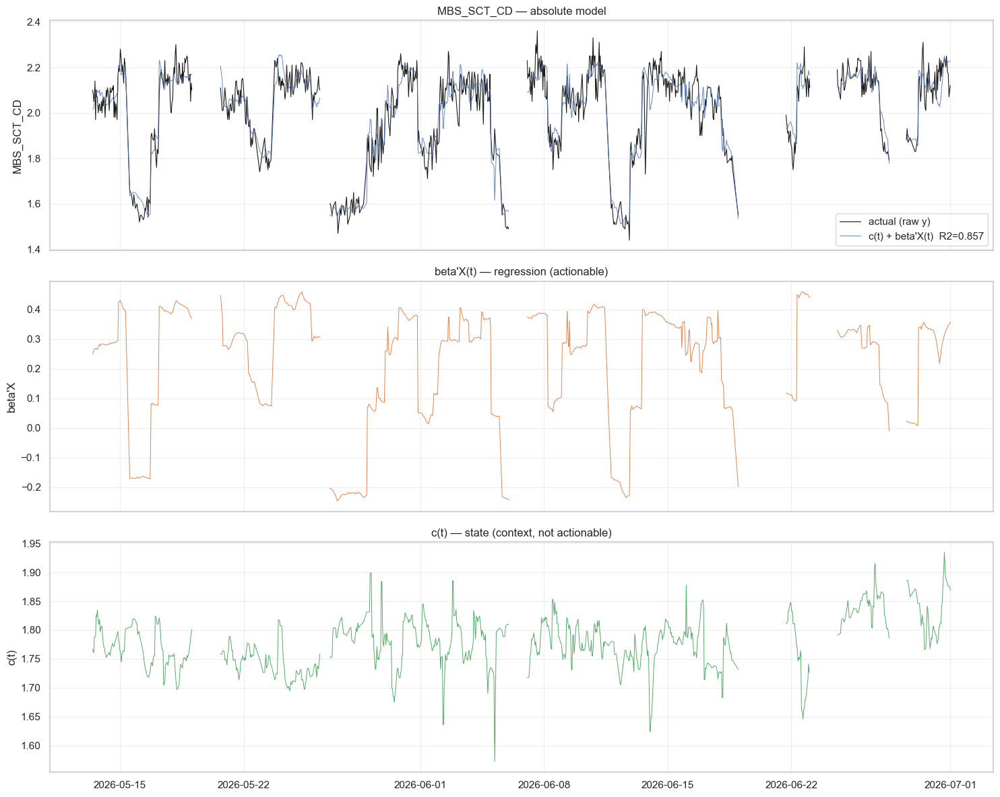

In [39]:
%matplotlib inline
# =============================================================================
# Extract fitted model and compute state column
# =============================================================================

import sys
sys.path.insert(0, str(Path.cwd().parent))
import cloudpickle
from utility import _feature_engineering, setpoint_df
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.metrics import r2_score, mean_absolute_error

# --- Load experiment artifacts ---
results_abs = json.load(open(best_path / 'results.json'))
with open(best_path / 'model.pkl', 'rb') as f:
    art = cloudpickle.load(f)

Y_COLUMN = results_abs['parameters']['y_column']
lag_days = results_abs['parameters']['lag_days']
ewm_halflife = results_abs['parameters'].get('ewm_halflife', '120min')
feature_cols = results_abs['data']['feature_cols']
feat_list = art['feat_list']
pre_estimator = art['pre_estimator']
selected_features = art.get('selected_features', feature_cols)

# Get the fitted model
raw_model = art['model']
est = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art and art['scaler'] is not None:
    est = SKPipeline([('scaler', art['scaler']), ('model', est)])

state_col = Y_COLUMN + '_state'

# Extract the exact test period from the experiment's turnup_ts
split_orig = results_abs['data']['split']
ts_artifact = pd.read_parquet(best_path / 'turnup_ts.parquet')
test_start = ts_artifact.index[split_orig]
test_end = ts_artifact.index[-1]
print(f'Experiment test period: {test_start} -> {test_end}')

# --- Load and prepare data ---
turnup_data = pd.read_parquet('../data/costimier_turnup.parquet')
turnup_data = _feature_engineering(turnup_data, setpoint_df, steam_null=False, clip=True)
turnup_data = turnup_data.set_index('Wedge_Time').sort_index()
turnup_data = turnup_data[turnup_data.grammage.isin([115, 120, 100, 90, 85, 110])]
turnup_ts = turnup_data.copy().sort_index()

print(f'Target: {Y_COLUMN}')
print(f'Lag: {lag_days}d, EWM halflife: {ewm_halflife}')
print(f'Pipeline steps: {[n for n, _ in pre_estimator.steps]}')
print(f'Selected features: {len(selected_features)}')
print(f'turnup_ts: {turnup_ts.shape}')

# --- EWM filter raw columns (data prep, not part of the model) ---
def ewm_filter_local(s, halflife=ewm_halflife):
    out = s.ewm(halflife=halflife, times=s.index, adjust=True).mean()
    if len(s) >= 2:
        out.iloc[0] = (s.iloc[0] + s.iloc[1]) / 2.0
    return out

grammage_group = turnup_ts['grammage'].values
grade_change = pd.Series(grammage_group).ne(pd.Series(grammage_group).shift())
time_gap = turnup_ts.index.to_series().diff().gt(pd.Timedelta('12h'))
time_gap.iloc[0] = True
seg = (grade_change.values | time_gap.values).cumsum()

y_raw = turnup_ts[Y_COLUMN].values.copy()

for col in feat_list:
    if col in turnup_ts.columns and pd.api.types.is_numeric_dtype(turnup_ts[col]):
        s = pd.Series(turnup_ts[col].values, index=turnup_ts.index)
        turnup_ts[col] = s.groupby(seg).transform(
            lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

y_ewm = pd.Series(y_raw, index=turnup_ts.index).groupby(seg).transform(
    lambda s: ewm_filter_local(s, halflife=ewm_halflife)).values

# --- Transform through pipeline (no EWM inside) ---
available_cols = [c for c in feat_list if c in turnup_ts.columns]
ts_transformed = pre_estimator.transform(turnup_ts.loc[:, available_cols])

# --- Compute beta'X for all rows ---
X_all = ts_transformed[selected_features].values.astype(float)
beta_X_all = est.predict(X_all).ravel()

# --- Lag pairing ---
def to_hours(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

t_hours = to_hours(ts_transformed.index)
later, earlier = lag_pairs(t_hours, lag_days * 24.0)

# --- Compute state: c(t) = y_ewm(t-k) - beta'X(t-k) ---
c = y_ewm[earlier] - beta_X_all[earlier]

turnup_ts[state_col] = np.nan
turnup_ts.iloc[later, turnup_ts.columns.get_loc(state_col)] = c
print(f'\nAdded "{state_col}": {turnup_ts[state_col].notna().sum()} valid values')

# --- Evaluate on the EXPERIMENT'S test period ---
y_hat = c + beta_X_all[later]
y_actual_ewm = y_ewm[later]
y_actual_raw = y_raw[later]
t_index = ts_transformed.index[later]

# Use the experiment's test boundary, not a recomputed split
test_mask = (t_index >= test_start) & (t_index <= test_end)

r2_ewm = r2_score(y_actual_ewm[test_mask], y_hat[test_mask])
r2_raw = r2_score(y_actual_raw[test_mask], y_hat[test_mask])

print(f'\n=== Absolute model (stored beta, no refit) ===')
print(f'  Test period: {t_index[test_mask][0]} -> {t_index[test_mask][-1]}')
print(f'  Test rows: {test_mask.sum()}')
print(f'  R2 vs EWM(y): {r2_ewm:.4f}')
print(f'  R2 vs raw y:  {r2_raw:.4f}')
print(f'  std(beta\'X): {np.std(beta_X_all[later[test_mask]]):.2f}  (regression)')
print(f'  std(c):       {np.std(c[test_mask]):.2f}  (state)')

# --- Plot ---
t_test = t_index[test_mask]
dt_h = np.diff(pd.DatetimeIndex(t_test).asi8.astype(float) / 3.6e12)
gaps = np.flatnonzero(dt_h > 12)
def gapped(vals):
    v = np.array(vals, dtype=float).copy()
    v[gaps] = np.nan
    return v

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)
axes[0].plot(t_test, gapped(y_actual_raw[test_mask]), lw=0.8, color='k', label='actual (raw y)')
axes[0].plot(t_test, gapped(y_hat[test_mask]), lw=0.7, color='C0', alpha=0.85,
             label=f'c(t) + beta\'X(t)  R2={r2_raw:.3f}')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title(f'{Y_COLUMN} — absolute model'); axes[0].set_ylabel(Y_COLUMN)

axes[1].plot(t_test, gapped(beta_X_all[later[test_mask]]), lw=0.7, color='C1')
axes[1].set_title("beta'X(t) — regression (actionable)"); axes[1].set_ylabel('beta\'X')
axes[1].grid(alpha=0.3)

axes[2].plot(t_test, gapped(c[test_mask]), lw=0.7, color='C2')
axes[2].set_title('c(t) — state (context, not actionable)'); axes[2].set_ylabel('c(t)')
axes[2].grid(alpha=0.3)
plt.tight_layout()


<Axes: xlabel='Wedge_Time'>

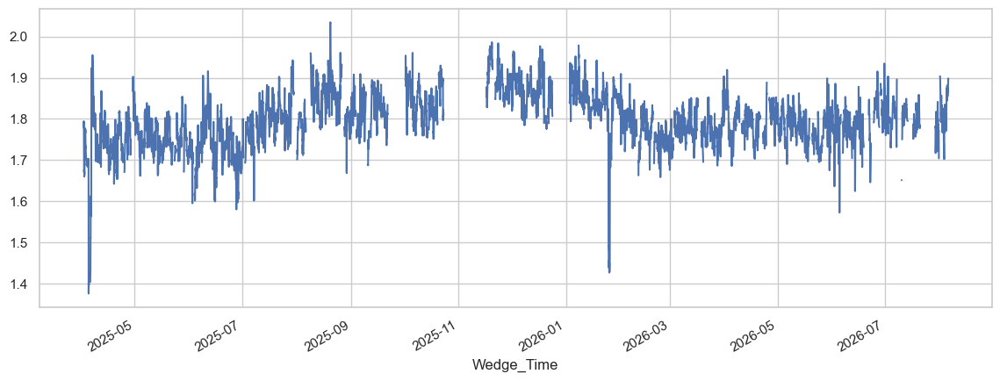

In [32]:
turnup_ts[state_col].plot()

In [67]:
# =============================================================================
# Production inference: predict a single row
# =============================================================================
# y_hat = (state + beta'X) * scale * row[multiplier] / row[divisor]
#
# - scale:      fixed numeric constant (e.g. unit conversion)
# - multiplier: column name; if set, prediction is multiplied by row[multiplier]
# - divisor:    column name; if set, prediction is divided by row[divisor]
#
# The multiplier and divisor columns are automatically appended to the list
# of required input variables.

class ProductionModel:
    def __init__(self, pre_estimator, estimator, feat_list, selected_features,
                 state_col, scale=1.0, multiplier=None, divisor=None):
        self.pre_estimator = pre_estimator
        self.estimator = estimator
        self.feat_list = list(feat_list)
        self.selected_features = selected_features
        self.state_col = state_col
        self.scale = scale
        self.multiplier = multiplier
        self.divisor = divisor

        # Append multiplier/divisor to required columns
        self.required_cols = list(feat_list) + [state_col]
        if multiplier and multiplier not in self.required_cols:
            self.required_cols.append(multiplier)
        if divisor and divisor not in self.required_cols:
            self.required_cols.append(divisor)

    def predict(self, row):
        """
        Predict y for a single row (Series from turnup_ts).
        The row must have feat_list columns + state_col + multiplier/divisor if set.
        """
        if isinstance(row, pd.DataFrame):
            if len(row) != 1:
                raise ValueError('pass a single row')
            row = row.iloc[0]

        state = row[self.state_col]
        if np.isnan(state):
            raise ValueError(f'{self.state_col} is NaN for this row')

        # Transform through pipeline
        cols = [c for c in self.feat_list if c in row.index]
        row_df = pd.DataFrame([row[cols]], columns=cols,
                              index=pd.DatetimeIndex([row.name]))
        X = self.pre_estimator.transform(row_df)
        beta_x = self.estimator.predict(X[self.selected_features].values)[0]

        result = float(state + beta_x) * self.scale

        if self.multiplier is not None:
            result = result * float(row[self.multiplier])
        if self.divisor is not None:
            result = result / float(row[self.divisor])

        return result

    def predict_batch(self, df):
        """Predict for multiple rows from turnup_ts."""
        return np.array([self.predict(df.iloc[i]) for i in range(len(df))])

    def sensitivity(self, row, feature, delta):
        """Effect of changing feature by delta. Returns (y_orig, y_mod, change)."""
        y_orig = self.predict(row)
        row_mod = row.copy()
        row_mod[feature] = row_mod[feature] + delta
        y_mod = self.predict(row_mod)
        return y_orig, y_mod, y_mod - y_orig

# Build it
# Example with no scale/multiplier/divisor (same as before):
prod_model = ProductionModel(
    pre_estimator, est, feat_list, selected_features, state_col,
    scale=1.0,         # fixed multiplier (e.g. unit conversion)
    multiplier=None,   # column name to multiply by, e.g. 'Production_Rate__T/h_'
    divisor=None,      # column name to divide by, e.g. 'Production_Rate__T/h_'
)

print(f'ProductionModel:')
print(f'  scale={prod_model.scale}')
print(f'  multiplier={prod_model.multiplier}')
print(f'  divisor={prod_model.divisor}')
print(f'  required_cols: {len(prod_model.required_cols)}')

# --- Test ---
test_row_idx = split_orig + 50
test_row = turnup_ts.iloc[test_row_idx].copy()
if not np.isnan(test_row[state_col]):
    y_pred_single = prod_model.predict(test_row)
    y_actual_single = turnup_ts[Y_COLUMN].iloc[test_row_idx]
    print(f'\nSingle-row prediction test:')
    print(f'  timestamp: {test_row.name}')
    print(f'  predicted: {y_pred_single:.4f}')
    print(f'  actual:    {y_actual_single:.4f}')
    print(f'  state:     {test_row[state_col]:.4f}')
else:
    print(f'Row {test_row_idx} has no valid state, trying another...')
    valid_test = turnup_ts.index[split_orig:][turnup_ts[state_col].iloc[split_orig:].notna()]
    if len(valid_test) > 0:
        test_row = turnup_ts.loc[valid_test[10]].copy()
        y_pred_single = prod_model.predict(test_row)
        print(f'  predicted: {y_pred_single:.4f}, '
              f'actual: {turnup_ts.loc[valid_test[10], Y_COLUMN]:.4f}')

# --- Sensitivity examples ---
print(f'\n--- Sensitivity ---')
for feat, delta in [('Jet/wire_ratio', 0.01), ('ambient_temp_C', 1.0),
                     ('White_water_temperature', 1.0)]:
    if feat in test_row.index:
        _, _, dy = prod_model.sensitivity(test_row, feat, delta)
        print(f'  {feat:35s}  +{delta:6.2f} -> dy = {dy:+.4f}')


ProductionModel:
  scale=1.0
  multiplier=None
  divisor=None
  required_cols: 39

Single-row prediction test:
  timestamp: 2025-09-20 10:48:30
  predicted: 2.0389
  actual:    65346.5430
  state:     1.7958

--- Sensitivity ---
  Jet/wire_ratio                       +  0.01 -> dy = +0.0000
  ambient_temp_C                       +  1.00 -> dy = +0.0000
  White_water_temperature              +  1.00 -> dy = +0.0015


=== Batch validation (from absolute model cell) ===
  R2 vs EWM(y) (test): 0.9383
  R2 vs raw y (test):  0.8570

=== Spot checks (single-row predict) ===
  2025-09-18 08:40:30  pred=   1.53  actual=   1.56  diff=-0.03
  2025-12-23 17:27:30  pred=   2.20  actual=   2.17  diff=+0.03
  2026-03-06 11:16:30  pred=   1.53  actual=   1.56  diff=-0.03
  2026-05-10 15:48:30  pred=   1.84  actual=   1.83  diff=+0.01
  2026-08-06 00:55:30  pred=   2.18  actual=   2.31  diff=-0.13


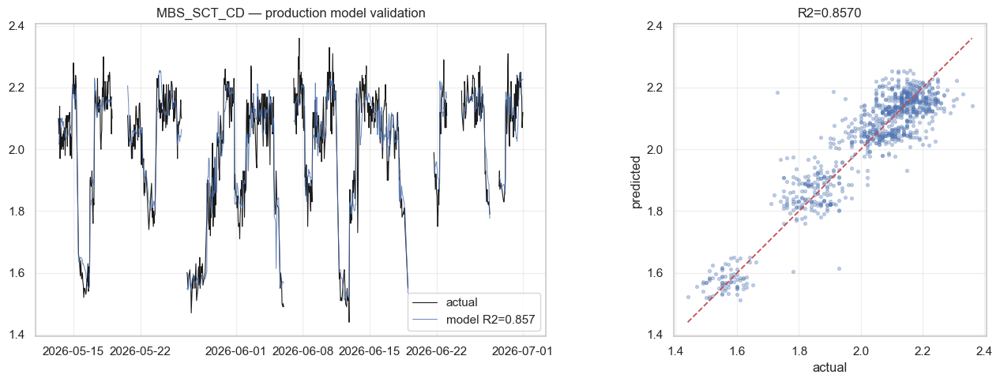

In [34]:
# =============================================================================
# Validate production model
# =============================================================================
# Batch: use the y_hat already computed in the absolute model cell.
# Spot checks: predict a few rows individually to verify the abstraction.

# --- Batch validation (already computed) ---
print(f'=== Batch validation (from absolute model cell) ===')
print(f'  R2 vs EWM(y) (test): {r2_ewm:.4f}')
print(f'  R2 vs raw y (test):  {r2_raw:.4f}')

# --- Spot checks: single-row inference ---
print(f'\n=== Spot checks (single-row predict) ===')
test_valid = turnup_ts.iloc[split_orig:]
test_valid = test_valid[test_valid[state_col].notna()]
n_checks = min(5, len(test_valid))
check_indices = np.linspace(0, len(test_valid) - 1, n_checks, dtype=int)

for idx in check_indices:
    row = test_valid.iloc[idx]
    try:
        y_pred = prod_model.predict(row)
        y_act = row[Y_COLUMN]
        print(f'  {row.name}  pred={y_pred:7.2f}  actual={y_act:7.2f}  diff={y_pred-y_act:+.2f}')
    except Exception as e:
        print(f'  {row.name}  FAILED: {type(e).__name__}: {e}')

# --- Plot (uses batch y_hat from absolute model cell) ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

t_test = t_index[test_mask]
dt_h = np.diff(pd.DatetimeIndex(t_test).asi8.astype(float) / 3.6e12)
gaps = np.flatnonzero(dt_h > 12)
def gapped_v(vals):
    v = np.array(vals, dtype=float).copy()
    v[gaps] = np.nan
    return v

axes[0].plot(t_test, gapped_v(y_actual_raw[test_mask]), lw=0.8, color='k', label='actual')
axes[0].plot(t_test, gapped_v(y_hat[test_mask]), lw=0.7, color='C0', alpha=0.85,
             label=f'model R2={r2_raw:.3f}')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title(f'{Y_COLUMN} — production model validation')

axes[1].scatter(y_actual_raw[test_mask], y_hat[test_mask], s=8, alpha=0.3)
lim = [min(y_actual_raw[test_mask].min(), y_hat[test_mask].min()),
       max(y_actual_raw[test_mask].max(), y_hat[test_mask].max())]
axes[1].plot(lim, lim, 'r--', lw=1.3)
axes[1].set_xlabel('actual'); axes[1].set_ylabel('predicted')
axes[1].set_title(f'R2={r2_raw:.4f}')
axes[1].set_aspect('equal', adjustable='box'); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [42]:
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')
# =============================================================================
# SHAP Analysis using model_full (trained on all data)
# =============================================================================
import sys
sys.path.insert(0, str(Path.cwd().parent))
import cloudpickle
from utility import calculate_manual_shap, plotly_shap_beeswarm

# Load the full model
with open(best_path / 'model_full.pkl', 'rb') as f:
    art_full = cloudpickle.load(f)

# Load differenced data
dX_train = pd.read_parquet(best_path / 'dX_train.parquet')
dX_test = pd.read_parquet(best_path / 'dX_test.parquet')

results_shap = json.load(open(best_path / 'results.json'))
feat_cols_shap = results_shap['data']['feature_cols']
selected_shap = art_full.get('selected_features', feat_cols_shap)

# Get the estimator
raw_model_full = art_full['model']
est_full = getattr(raw_model_full, 'best_estimator_', raw_model_full)
if 'scaler' in art_full and art_full['scaler'] is not None:
    from sklearn.pipeline import Pipeline as SKPipeline
    est_full = SKPipeline([('scaler', art_full['scaler']), ('model', est_full)])

# Use ALL data as both reference and sample (model_full saw everything)
dX_all = pd.concat([dX_train, dX_test], ignore_index=False)

# Keep only selected features + grade col
model_cols = [c for c in selected_shap if c in dX_all.columns]

# Wrap model to drop AB_Grade_ID before predicting
class _ModelWrapperFull:
    def __init__(self, estimator, cols):
        self.estimator = estimator
        self.cols = cols
    def predict(self, X):
        Xf = X[self.cols] if isinstance(X, pd.DataFrame) else X
        return self.estimator.predict(Xf)

wrapped_full = _ModelWrapperFull(est_full, model_cols)

# Compute SHAP
grade_id = '6010120'  # or None for all grades
base, shap_vals, X_explain, feats = calculate_manual_shap(
    wrapped_full,
    X_sample=dX_all[model_cols + ['AB_Grade_ID']],
    X_reference=dX_all[model_cols + ['AB_Grade_ID']],
    grade_col='AB_Grade_ID',
    grade_id=grade_id,
)

print(f'SHAP (model_full): {shap_vals.shape[0]} samples, {shap_vals.shape[1]} features')
print(f'Grade: {grade_id}')

fig = plotly_shap_beeswarm(shap_vals, X_explain, feats, max_features=100)
fig.show()


PermutationExplainer explainer: 1609it [00:39, 30.29it/s]                          


SHAP (model_full): 1608 samples, 20 features
Grade: 6010120


In [43]:
import warnings
warnings.filterwarnings('ignore')
# =============================================================================
# SHAP on RAW features (direct Ridge on raw differenced data)
# =============================================================================
# Fits a Ridge directly on EWM'd raw features (no PLS, no engineering)
# to get SHAP values on the original column names.

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score

# Load artifacts
results_raw = json.load(open(best_path / 'results.json'))
Y_COL_RAW = results_raw['parameters']['y_column']
lag_raw = results_raw['parameters']['lag_days']
ewm_hl_raw = results_raw['parameters'].get('ewm_halflife', '120min')
split_raw = results_raw['data']['split']

with open(best_path / 'model_full.pkl', 'rb') as f:
    art_raw_full = cloudpickle.load(f)
feat_list_raw = art_raw_full['feat_list']

# Load the EWM'd turnup_ts from artifact
ts_ewm = pd.read_parquet(best_path / 'turnup_ts.parquet')

# Raw numeric columns (exclude AB_Grade_ID and non-numeric)
numeric_cols = [c for c in feat_list_raw
                if c in ts_ewm.columns
                and c != 'AB_Grade_ID'
                and pd.api.types.is_numeric_dtype(ts_ewm[c])]

# Lag pairing
def to_hours_raw(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs_raw(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

t_hrs_raw = to_hours_raw(ts_ewm.index)
later_raw, earlier_raw = lag_pairs_raw(t_hrs_raw, lag_raw * 24.0)

# Differenced raw features
X_raw_all = ts_ewm[numeric_cols].values.astype(float)
y_ewm_raw = ts_ewm[Y_COL_RAW].values.astype(float)
dX_raw_all = X_raw_all[later_raw] - X_raw_all[earlier_raw]
dy_raw_all = y_ewm_raw[later_raw] - y_ewm_raw[earlier_raw]

# Fit Ridge on ALL raw differenced data (matches model_full)
model_raw_full = GridSearchCV(
    Pipeline([('scaler', StandardScaler()), ('ridge', Ridge())]),
    param_grid={'ridge__alpha': np.logspace(0, 3, 20).tolist()},
    cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_root_mean_squared_error',
    refit=True,
)
model_raw_full.fit(dX_raw_all, dy_raw_all)

r2_raw_direct = r2_score(dy_raw_all, model_raw_full.predict(dX_raw_all))
r2_prod = results_raw['metrics']['dy']['r2']
print(f'R2(dy) raw features model: {r2_raw_direct:.4f}')
print(f'R2(dy) production model:   {r2_prod:.4f}')
print(f'Gap (PLS/engineering value): {r2_prod - r2_raw_direct:+.4f}')

# SHAP on raw features
dX_raw_df = pd.DataFrame(dX_raw_all, columns=numeric_cols)
dX_raw_df['AB_Grade_ID'] = ts_ewm['AB_Grade_ID'].values[later_raw]

class _RawWrap:
    def __init__(self, model, cols):
        self.model = model
        self.cols = cols
    def predict(self, X):
        Xf = X[self.cols] if isinstance(X, pd.DataFrame) else X
        return self.model.predict(Xf)

wrapped_raw_full = _RawWrap(model_raw_full.best_estimator_, numeric_cols)

grade_id_raw = '6010120'  # or None for all grades
base_r, shap_vals_r, X_explain_r, feats_r = calculate_manual_shap(
    wrapped_raw_full,
    X_sample=dX_raw_df,
    X_reference=dX_raw_df,
    grade_col='AB_Grade_ID',
    grade_id=grade_id_raw,
)

print(f'\nSHAP (raw features, model_full): {shap_vals_r.shape[0]} samples, {shap_vals_r.shape[1]} features')

fig = plotly_shap_beeswarm(shap_vals_r, X_explain_r, feats_r, max_features=50)
fig.show()


R2(dy) raw features model: 0.8934
R2(dy) production model:   0.8304
Gap (PLS/engineering value): -0.0630


PermutationExplainer explainer: 1609it [01:03, 21.46it/s]                          



SHAP (raw features, model_full): 1608 samples, 38 features


In [66]:
best_path

WindowsPath('experiments/differencing/Steam_power_corrected/260827161406')

Target: Steam_power_corrected
Lag: 0.25d, EWM halflife: 8h
Selected features: 10

=== Model performance ===
  R2 vs EWM(y):  0.9539
  R2 vs raw y:   0.8839

=== Specific steam: Steam_power_corrected / Production_Rate__T/h_ ===
  Test points: 620
  R2:  0.4175
  MAE: 16.6597

ProductionModel: scale=1.0, divisor=Production_Rate__T/h_, required_cols=114


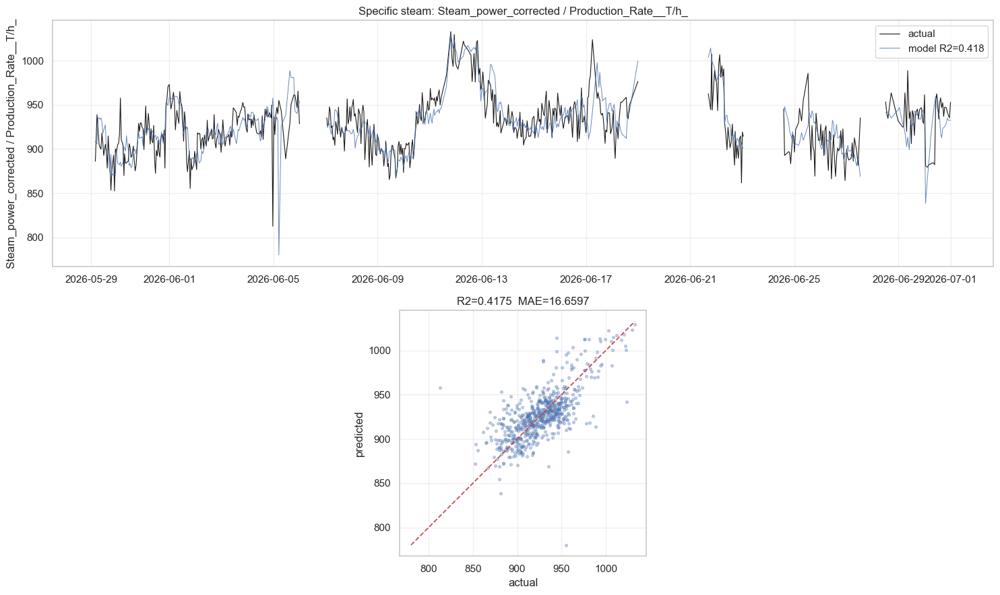

In [69]:
%matplotlib inline
# =============================================================================
# Self-contained: load model, build ProductionModel, predict, evaluate
# =============================================================================
# Only depends on `best_path` from the experiment loading cell.

import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cloudpickle
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.metrics import r2_score, mean_absolute_error

# --- Load artifacts ---
results_sp = json.load(open(best_path / 'results.json'))
with open(best_path / 'model.pkl', 'rb') as f:
    art_sp = cloudpickle.load(f)

Y_COLUMN = results_sp['parameters']['y_column']
lag_days = results_sp['parameters']['lag_days']
ewm_halflife = results_sp['parameters'].get('ewm_halflife', '120min')
split_sp = results_sp['data']['split']
feature_cols = results_sp['data']['feature_cols']
feat_list = art_sp['feat_list']
pre_estimator = art_sp['pre_estimator']
selected_features = art_sp.get('selected_features', feature_cols)

raw_model = art_sp['model']
est = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art_sp and art_sp['scaler'] is not None:
    est = SKPipeline([('scaler', art_sp['scaler']), ('model', est)])

state_col = Y_COLUMN + '_state'
div_col = 'Production_Rate__T/h_'

print(f'Target: {Y_COLUMN}')
print(f'Lag: {lag_days}d, EWM halflife: {ewm_halflife}')
print(f'Selected features: {len(selected_features)}')

# --- Load data from artifacts ---
ts_ewm = pd.read_parquet(best_path / 'turnup_ts.parquet')      # EWM'd
ts_raw = pd.read_parquet(best_path / 'turnup_ts_raw.parquet')   # raw

# --- Helpers ---
def to_hours(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

# --- Transform EWM'd data through the pipeline ---
avail = [c for c in feat_list if c in ts_ewm.columns]
ts_transformed = pre_estimator.transform(ts_ewm.loc[:, avail])

# --- Compute beta'X and state ---
X_all = ts_transformed[selected_features].values.astype(float)
beta_X_all = est.predict(X_all).ravel()
y_ewm = ts_ewm[Y_COLUMN].values.astype(float)
y_raw = ts_raw[Y_COLUMN].reindex(ts_ewm.index).values

t_hours_all = to_hours(ts_transformed.index)
later, earlier = lag_pairs(t_hours_all, lag_days * 24.0)

c_state = y_ewm[earlier] - beta_X_all[earlier]
y_hat = c_state + beta_X_all[later]
y_actual_raw = y_raw[later]
t_index = ts_transformed.index[later]
test_mask = t_index >= ts_ewm.index[split_sp]

# --- Production Rate from raw data ---
prod_rate = ts_raw[div_col].reindex(t_index[test_mask]).values

# --- Specific steam ---
valid = (prod_rate > 0) & ~np.isnan(prod_rate) & ~np.isnan(y_hat[test_mask]) & ~np.isnan(y_actual_raw[test_mask])
pred_specific = y_hat[test_mask][valid] / prod_rate[valid]
actual_specific = y_actual_raw[test_mask][valid] / prod_rate[valid]
t_valid = t_index[test_mask][valid]

r2_sp = r2_score(actual_specific, pred_specific)
mae_sp = mean_absolute_error(actual_specific, pred_specific)

# Also report the base model performance
r2_ewm_base = r2_score(y_ewm[later[test_mask]], y_hat[test_mask])
r2_raw_base = r2_score(y_actual_raw[test_mask], y_hat[test_mask])

print(f'\n=== Model performance ===')
print(f'  R2 vs EWM(y):  {r2_ewm_base:.4f}')
print(f'  R2 vs raw y:   {r2_raw_base:.4f}')
print(f'\n=== Specific steam: {Y_COLUMN} / {div_col} ===')
print(f'  Test points: {len(pred_specific)}')
print(f'  R2:  {r2_sp:.4f}')
print(f'  MAE: {mae_sp:.4f}')

# --- ProductionModel for deployment ---
class ProductionModel:
    def __init__(self, pre_estimator, estimator, feat_list, selected_features,
                 state_col, scale=1.0, multiplier=None, divisor=None):
        self.pre_estimator = pre_estimator
        self.estimator = estimator
        self.feat_list = list(feat_list)
        self.selected_features = selected_features
        self.state_col = state_col
        self.scale = scale
        self.multiplier = multiplier
        self.divisor = divisor
        self.required_cols = list(feat_list) + [state_col]
        if multiplier and multiplier not in self.required_cols:
            self.required_cols.append(multiplier)
        if divisor and divisor not in self.required_cols:
            self.required_cols.append(divisor)

    def predict(self, row):
        if isinstance(row, pd.DataFrame):
            if len(row) != 1:
                raise ValueError('pass a single row')
            row = row.iloc[0]
        state = row[self.state_col]
        if np.isnan(state):
            raise ValueError(f'{self.state_col} is NaN')
        cols = [c for c in self.feat_list if c in row.index]
        row_df = pd.DataFrame([row[cols]], columns=cols,
                              index=pd.DatetimeIndex([row.name]))
        X = self.pre_estimator.transform(row_df)
        beta_x = self.estimator.predict(X[self.selected_features].values)[0]
        result = float(state + beta_x) * self.scale
        if self.multiplier is not None:
            result *= float(row[self.multiplier])
        if self.divisor is not None:
            result /= float(row[self.divisor])
        return result

    def sensitivity(self, row, feature, delta):
        y_orig = self.predict(row)
        row_mod = row.copy()
        row_mod[feature] += delta
        return y_orig, self.predict(row_mod), self.predict(row_mod) - y_orig

prod_model = ProductionModel(
    pre_estimator, est, feat_list, selected_features, state_col,
    scale=1.0, multiplier=None, divisor=div_col,
)
print(f'\nProductionModel: scale={prod_model.scale}, '
      f'divisor={prod_model.divisor}, '
      f'required_cols={len(prod_model.required_cols)}')

# --- Plot ---
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

dt_h = np.diff(pd.DatetimeIndex(t_valid).asi8.astype(float) / 3.6e12)
gaps = np.flatnonzero(dt_h > 12)
def gapped_sp(vals):
    v = np.array(vals, dtype=float).copy()
    v[gaps] = np.nan
    return v

axes[0].plot(t_valid, gapped_sp(actual_specific), lw=0.8, color='k', label='actual')
axes[0].plot(t_valid, gapped_sp(pred_specific), lw=0.7, color='C0', alpha=0.85,
             label=f'model R2={r2_sp:.3f}')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title(f'Specific steam: {Y_COLUMN} / {div_col}')
axes[0].set_ylabel(f'{Y_COLUMN} / {div_col}')

axes[1].scatter(actual_specific, pred_specific, s=8, alpha=0.3)
lim = [min(actual_specific.min(), pred_specific.min()),
       max(actual_specific.max(), pred_specific.max())]
axes[1].plot(lim, lim, 'r--', lw=1.3)
axes[1].set_xlabel('actual'); axes[1].set_ylabel('predicted')
axes[1].set_title(f'R2={r2_sp:.4f}  MAE={mae_sp:.4f}')
axes[1].set_aspect('equal', adjustable='box'); axes[1].grid(alpha=0.3)
plt.tight_layout()


Target: MBS_SCT_CD
Lag: 0.25d, EWM halflife: 4h
Selected features: 20

=== Model performance (MBS_SCT_CD) ===
  Test points:   914
  R2 vs EWM(y):  0.9383
  R2 vs raw y:   0.8575
  MAE vs raw y:  0.0549

ProductionModel: scale=1.0, multiplier=None, divisor=None, required_cols=39


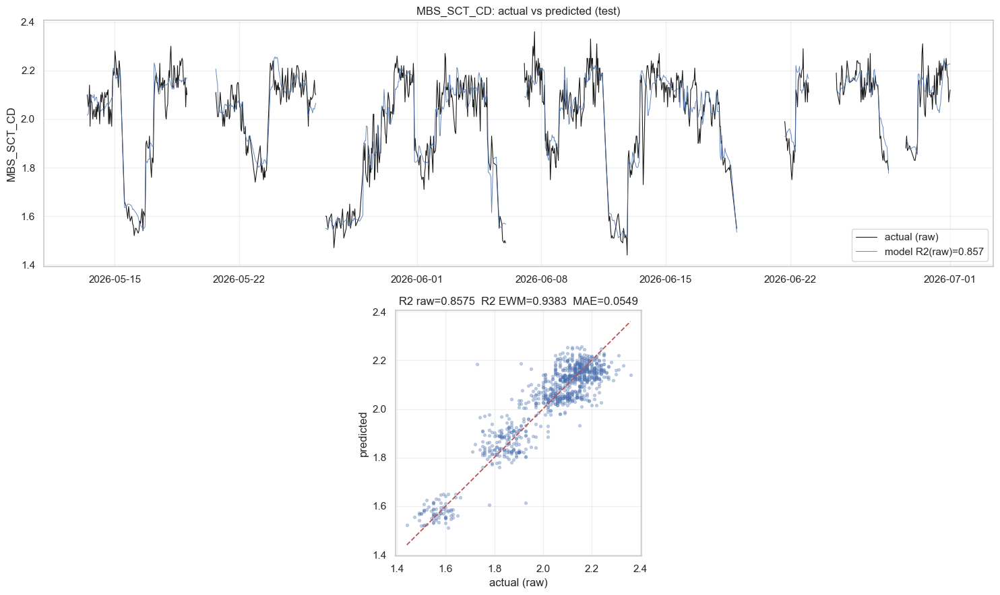

In [5]:
%matplotlib inline
# =============================================================================
# Self-contained: SCT_CD model (no scale, no multiplier, no divisor)
# =============================================================================
# Only depends on `best_path` from the experiment loading cell.

import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cloudpickle
from sklearn.pipeline import Pipeline as SKPipeline
from sklearn.metrics import r2_score, mean_absolute_error

# --- Load artifacts ---
results_sct = json.load(open(best_path / 'results.json'))
with open(best_path / 'model.pkl', 'rb') as f:
    art_sct = cloudpickle.load(f)

Y_COLUMN = results_sct['parameters']['y_column']
lag_days = results_sct['parameters']['lag_days']
ewm_halflife = results_sct['parameters'].get('ewm_halflife', '120min')
split_sct = results_sct['data']['split']
feature_cols = results_sct['data']['feature_cols']
feat_list = art_sct['feat_list']
pre_estimator = art_sct['pre_estimator']
selected_features = art_sct.get('selected_features', feature_cols)

raw_model = art_sct['model']
est = getattr(raw_model, 'best_estimator_', raw_model)
if 'scaler' in art_sct and art_sct['scaler'] is not None:
    est = SKPipeline([('scaler', art_sct['scaler']), ('model', est)])

state_col = Y_COLUMN + '_state'

print(f'Target: {Y_COLUMN}')
print(f'Lag: {lag_days}d, EWM halflife: {ewm_halflife}')
print(f'Selected features: {len(selected_features)}')

# --- Load data from artifacts ---
ts_ewm = pd.read_parquet(best_path / 'turnup_ts.parquet')      # EWM'd
ts_raw = pd.read_parquet(best_path / 'turnup_ts_raw.parquet')   # raw

# --- Helpers ---
def to_hours(index):
    t = pd.DatetimeIndex(index).asi8.astype(np.float64)
    return (t - t[0]) / 3.6e12

def lag_pairs(t_hours, lag_hours, tolerance=0.35):
    target = t_hours - lag_hours
    j = np.searchsorted(t_hours, target)
    j = np.clip(j, 0, len(t_hours) - 1)
    j_alt = np.clip(j - 1, 0, len(t_hours) - 1)
    better = np.abs(t_hours[j_alt] - target) < np.abs(t_hours[j] - target)
    j = np.where(better, j_alt, j)
    realised = t_hours - t_hours[j]
    ok = (j < np.arange(len(t_hours))) & (np.abs(realised - lag_hours) <= tolerance * lag_hours)
    later = np.flatnonzero(ok)
    return later, j[later]

# --- Transform EWM'd data through the pipeline ---
avail = [c for c in feat_list if c in ts_ewm.columns]
ts_transformed = pre_estimator.transform(ts_ewm.loc[:, avail])

# --- Compute beta'X and state ---
X_all = ts_transformed[selected_features].values.astype(float)
beta_X_all = est.predict(X_all).ravel()
y_ewm = ts_ewm[Y_COLUMN].values.astype(float)
y_raw = ts_raw[Y_COLUMN].reindex(ts_ewm.index).values

t_hours_all = to_hours(ts_transformed.index)
later, earlier = lag_pairs(t_hours_all, lag_days * 24.0)

c_state = y_ewm[earlier] - beta_X_all[earlier]
y_hat = c_state + beta_X_all[later]
y_actual_raw = y_raw[later]
y_actual_ewm = y_ewm[later]
t_index = ts_transformed.index[later]
test_mask = t_index >= ts_ewm.index[split_sct]

# --- Model performance (no scale / multiplier / divisor) ---
valid = ~np.isnan(y_hat[test_mask]) & ~np.isnan(y_actual_raw[test_mask])
pred = y_hat[test_mask][valid]
actual_raw = y_actual_raw[test_mask][valid]
actual_ewm = y_actual_ewm[test_mask][valid]
t_valid = t_index[test_mask][valid]

r2_ewm_base = r2_score(actual_ewm, pred)
r2_raw_base = r2_score(actual_raw, pred)
mae_raw_base = mean_absolute_error(actual_raw, pred)

print(f'\n=== Model performance ({Y_COLUMN}) ===')
print(f'  Test points:   {len(pred)}')
print(f'  R2 vs EWM(y):  {r2_ewm_base:.4f}')
print(f'  R2 vs raw y:   {r2_raw_base:.4f}')
print(f'  MAE vs raw y:  {mae_raw_base:.4f}')

# --- ProductionModel for deployment ---
class ProductionModel:
    def __init__(self, pre_estimator, estimator, feat_list, selected_features,
                 state_col, scale=1.0, multiplier=None, divisor=None):
        self.pre_estimator = pre_estimator
        self.estimator = estimator
        self.feat_list = list(feat_list)
        self.selected_features = selected_features
        self.state_col = state_col
        self.scale = scale
        self.multiplier = multiplier
        self.divisor = divisor
        self.required_cols = list(feat_list) + [state_col]
        if multiplier and multiplier not in self.required_cols:
            self.required_cols.append(multiplier)
        if divisor and divisor not in self.required_cols:
            self.required_cols.append(divisor)

    def predict(self, row):
        if isinstance(row, pd.DataFrame):
            if len(row) != 1:
                raise ValueError('pass a single row')
            row = row.iloc[0]
        state = row[self.state_col]
        if np.isnan(state):
            raise ValueError(f'{self.state_col} is NaN')
        cols = [c for c in self.feat_list if c in row.index]
        row_df = pd.DataFrame([row[cols]], columns=cols,
                              index=pd.DatetimeIndex([row.name]))
        X = self.pre_estimator.transform(row_df)
        beta_x = self.estimator.predict(X[self.selected_features].values)[0]
        result = float(state + beta_x) * self.scale
        if self.multiplier is not None:
            result *= float(row[self.multiplier])
        if self.divisor is not None:
            result /= float(row[self.divisor])
        return result

    def sensitivity(self, row, feature, delta):
        y_orig = self.predict(row)
        row_mod = row.copy()
        row_mod[feature] += delta
        return y_orig, self.predict(row_mod), self.predict(row_mod) - y_orig

prod_model = ProductionModel(
    pre_estimator, est, feat_list, selected_features, state_col,
    scale=1.0, multiplier=None, divisor=None,
)
print(f'\nProductionModel: scale={prod_model.scale}, '
      f'multiplier={prod_model.multiplier}, divisor={prod_model.divisor}, '
      f'required_cols={len(prod_model.required_cols)}')

# --- Plot ---
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

dt_h = np.diff(pd.DatetimeIndex(t_valid).asi8.astype(float) / 3.6e12)
gaps = np.flatnonzero(dt_h > 12)
def gapped(vals):
    v = np.array(vals, dtype=float).copy()
    v[gaps] = np.nan
    return v

axes[0].plot(t_valid, gapped(actual_raw), lw=0.8, color='k', label='actual (raw)')
axes[0].plot(t_valid, gapped(pred), lw=0.7, color='C0', alpha=0.85,
             label=f'model R2(raw)={r2_raw_base:.3f}')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title(f'{Y_COLUMN}: actual vs predicted (test)')
axes[0].set_ylabel(Y_COLUMN)

axes[1].scatter(actual_raw, pred, s=8, alpha=0.3)
lim = [min(actual_raw.min(), pred.min()),
       max(actual_raw.max(), pred.max())]
axes[1].plot(lim, lim, 'r--', lw=1.3)
axes[1].set_xlabel('actual (raw)'); axes[1].set_ylabel('predicted')
axes[1].set_title(f'R2 raw={r2_raw_base:.4f}  R2 EWM={r2_ewm_base:.4f}  MAE={mae_raw_base:.4f}')
axes[1].set_aspect('equal', adjustable='box'); axes[1].grid(alpha=0.3)
plt.tight_layout()


# Deployment

Shared EWM filter + one state column per model.

**`TurnupFilter` (one, shared across all models).** Owns the EWM filtering at a single
common halflife (`EWM_HALFLIFE`). Model-agnostic: it filters whatever columns it is told
to. The exact EWM (grade-aware, gap-segmented, time-aware `adjust=True`, softened start)
lives inside it. The engine passes the whole raw turnup, the columns to filter, and the
timestamps it wants output for; the filter slices whatever in-segment look-back it needs.
`filter_all` is the source of truth; `filter(timestamps)` matches it to ~1e-6.

**State object, one per model (`StateBuilder`).** Consumes an already-EWM-filtered frame
and computes `c(t) = y_ewm(t-k) - beta'X(t-k)` -> `Y_COLUMN + "_state"`. It runs the
model's `pre_estimator` (FeatureCreator -> PLS -> filter -> Scaler, all row-local) and the
fitted `beta`, plus lag pairing. No EWM inside it anymore.

**`ProductionModel`, one per model.** Consumes the `*_state` column and returns
`(state + beta'X) * scale * multiplier / divisor`.

**Engine flow:** load raw turnup -> `filtered = turnup_filter.filter(turnup_raw, cols, ts)`
(once, shared) -> per model `state_builder.append_state(filtered)` -> `production_model.predict(...)`.

**Hard requirement:** every deployed model must have been trained at `EWM_HALFLIFE`.


In [5]:
# Deployment objects now live in utility.py (imported by reference so cloudpickle
# bundles are portable across Python minor versions). See utility.TurnupFilter,
# StateBuilder, ProductionModel, load_state_and_prod.
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import cloudpickle

from utility import TurnupFilter, StateBuilder, ProductionModel, load_state_and_prod

print('Imported TurnupFilter, StateBuilder, ProductionModel, load_state_and_prod from utility.')


Imported TurnupFilter, StateBuilder, ProductionModel, load_state_and_prod from utility.


In [6]:
# --- Demo: shared filter -> per-model state -> predict (Wedge_Time index, reel-id select) ---
# Depends on best_path and EWM_HALFLIFE.
import sys
sys.path.insert(0, str(Path.cwd().parent))
from utility import _feature_engineering, setpoint_df
from sklearn.metrics import r2_score, mean_absolute_error

builder, prod_model = load_state_and_prod(
    best_path, use_full_model=False,   # model.pkl to reproduce test numbers
    scale=1.0, multiplier=None, divisor=None,
)
turnup_filter = TurnupFilter(halflife=EWM_HALFLIFE)
print(f'Target: {builder.y_column} | lag={builder.lag_days}d | halflife(model)={builder.ewm_halflife} '
      f'| filter halflife={turnup_filter.halflife}')

# raw turnup (feature-engineered), Wedge_Time-indexed, reel id as a column
turnup = pd.read_parquet('../data/costimier_turnup.parquet')
turnup = _feature_engineering(turnup, setpoint_df, steam_null=False, clip=True)
turnup = turnup.set_index('Wedge_Time').sort_index()
turnup = turnup[turnup.grammage.isin([115, 120, 100, 90, 85, 110])]

# 1) shared filter (batch) -> Wedge_Time-indexed, reel id column
cols_to_filter = builder.feat_list + [builder.y_column]
filtered = turnup_filter.filter_all(turnup, cols_to_filter)

# 2) per-model state (all rows) -> Wedge_Time-indexed
filtered = builder.append_state(filtered)
print(f'Added "{builder.state_col}": {filtered[builder.state_col].notna().sum()} valid values '
      f'(index = {filtered.index.name})')

# 3) predict (batch) on rows with a valid state
eval_df = filtered[filtered[builder.state_col].notna()].copy()
y_hat = prod_model.predict(eval_df)
y_true = turnup[builder.y_column].reindex(eval_df.index).values.astype(float)
ok = ~np.isnan(y_hat) & ~np.isnan(y_true)
print(f'ProductionModel vs raw y: R2={r2_score(y_true[ok], y_hat[ok]):.4f}  '
      f'MAE={mean_absolute_error(y_true[ok], y_hat[ok]):.4f}  (n={ok.sum()})')


Target: MBS_SCT_MD | lag=0.25d | halflife(model)=6h | filter halflife=6h
Added "MBS_SCT_MD_state": 9340 valid values (index = Wedge_Time)
ProductionModel vs raw y: R2=0.9204  MAE=0.0960  (n=9340)


In [7]:
# --- Save deployment bundle for the engine (cloudpickle here) ---
# Emits: deploy/turnup_filter.pkl, deploy/<Y_COLUMN>_bundle.pkl, deploy/manifest.json
# Engine needs: cloudpickle, numpy, pandas, and `utility` importable.
import cloudpickle, json
from pathlib import Path

DEPLOY_DIR = Path('deploy')
DEPLOY_DIR.mkdir(exist_ok=True)

# ---- 1. The shared filter (one, at EWM_HALFLIFE) ----
turnup_filter_save = TurnupFilter(halflife=EWM_HALFLIFE)
with open(DEPLOY_DIR / 'turnup_filter.pkl', 'wb') as f:
    cloudpickle.dump(turnup_filter_save, f)

# ---- 2. Per-model bundle (state builder + production model), FULL model ----
# Set per-model scale/multiplier/divisor here. SCT_CD: all defaults.
builder_save, prod_save = load_state_and_prod(
    best_path, use_full_model=True, scale=1.0, multiplier=None, divisor=None,
    max_tolerance=1.0, fill='ffill',   # bake NaN-reduction into the shipped model
)
model_bundle = {
    'y_column':         builder_save.y_column,
    'state_col':        builder_save.state_col,
    'lag_days':         builder_save.lag_days,
    'ewm_halflife':     builder_save.ewm_halflife,
    'feat_list':        builder_save.feat_list,
    'input_features':   list(prod_save.feature_names_in_),
    'max_tolerance':    builder_save.max_tolerance,
    'fill':             builder_save.fill,
    'state_builder':    builder_save,
    'production_model': prod_save,
}
model_pkl = DEPLOY_DIR / f'{builder_save.y_column}_bundle.pkl'
with open(model_pkl, 'wb') as f:
    cloudpickle.dump(model_bundle, f)

# ---- 3. Manifest (halflife, required columns union, model list) ----
# required_columns = union of every model's feat_list + every y_column.
# With one model here it's just this model's; extend when packing more.
manifest_path = DEPLOY_DIR / 'manifest.json'
if manifest_path.exists():
    manifest = json.load(open(manifest_path))
else:
    manifest = {'ewm_halflife': EWM_HALFLIFE, 'required_columns': [], 'models': []}

manifest['ewm_halflife'] = EWM_HALFLIFE
req = set(manifest.get('required_columns', []))
req.update(builder_save.feat_list)
req.add(builder_save.y_column)
manifest['required_columns'] = sorted(req)
models = {m['y_column']: m for m in manifest.get('models', [])}
models[builder_save.y_column] = {
    'y_column': builder_save.y_column,
    'state_col': builder_save.state_col,
    'lag_days': builder_save.lag_days,
    'ewm_halflife': builder_save.ewm_halflife,
    'pkl': model_pkl.name,
    'input_features': list(prod_save.feature_names_in_),
    'max_tolerance': builder_save.max_tolerance,
    'fill': builder_save.fill,
}
manifest['models'] = list(models.values())
json.dump(manifest, open(manifest_path, 'w'), indent=2)

print(f'Saved: {DEPLOY_DIR / "turnup_filter.pkl"}')
print(f'       {model_pkl}')
print(f'       {manifest_path}')
print(f'  halflife={EWM_HALFLIFE}  required_columns={len(manifest["required_columns"])}  '
      f'models={[m["y_column"] for m in manifest["models"]]}')
if builder_save.ewm_halflife != EWM_HALFLIFE:
    print(f'  WARNING: model trained at {builder_save.ewm_halflife} but filter is {EWM_HALFLIFE} '
          f'-- state will be inconsistent. Retrain this model at {EWM_HALFLIFE}.')


Saved: deploy\turnup_filter.pkl
       deploy\MBS_SCT_MD_bundle.pkl
       deploy\manifest.json
  halflife=6h  required_columns=131  models=['Steam_power_corrected', 'MBS_SCT_CD', 'MBS_SCT_MD']


In [ ]:
# --- Equivalence tests (Wedge_Time index, reel-id selection) ---
import numpy as np, pandas as pd

cols_to_filter = builder_save.feat_list + [builder_save.y_column]
filtered_all = turnup_filter_save.filter_all(turnup, cols_to_filter)   # Wedge_Time-indexed

# segment-oldest rows differ by design (softened start needs a NEWER row); excluded below.
seg = pd.Series(turnup_filter_save.segments(turnup), index=turnup.sort_index().index)
is_oldest = ~seg.duplicated(keep='first')
oldest_reels = set(turnup.sort_index().loc[is_oldest.values, 'MBS_Current_reel_ID'].values)
id_all = turnup.sort_index()['MBS_Current_reel_ID'].values
non_oldest_reels = [r for r in id_all if r not in oldest_reels]

# (a) filter(reel_ids) == filter_all on the selected non-oldest reels (exact)
sample_reels = list(np.array(non_oldest_reels)[np.linspace(0, len(non_oldest_reels)-1, 25).astype(int)])
fp = turnup_filter_save.filter(turnup, cols_to_filter, sample_reels)
# align by reel id (Wedge_Time index differs only in ordering)
fp_by_id = fp.set_index('MBS_Current_reel_ID')
fa_by_id = filtered_all.set_index('MBS_Current_reel_ID')
diff = fp_by_id.loc[sample_reels, cols_to_filter].values - fa_by_id.loc[sample_reels, cols_to_filter].values
print(f'(a) filter vs filter_all (non-oldest reels)  max|diff| = {np.nanmax(np.abs(diff)):.2e}')

# (b) engine path (shared filter -> state) == all-in-one
state_engine = builder_save.append_state(filtered_all.copy())[builder_save.state_col].values
state_allin1 = builder_save.append_state_from_raw(turnup, turnup_filter_save)[builder_save.state_col].values
m = ~np.isnan(state_engine) & ~np.isnan(state_allin1)
print(f'(b) state engine vs all-in-one  max|diff| = {np.nanmax(np.abs(state_engine[m]-state_allin1[m])):.2e}  (n={m.sum()})')

# (c) reel-id selection in append_state: subset == full on selected reels
sel = sample_reels[:8]
full_state = builder_save.append_state(filtered_all.copy())
sub_state  = builder_save.append_state(filtered_all.copy(), reel_ids=sel)
fs = full_state.set_index('MBS_Current_reel_ID')[builder_save.state_col].reindex(sel).values
ss = sub_state.set_index('MBS_Current_reel_ID')[builder_save.state_col].reindex(sel).values
mm = ~np.isnan(fs) & ~np.isnan(ss)
print(f'(c) append_state(reel_ids) vs full  max|diff| = {np.nanmax(np.abs(fs[mm]-ss[mm])) if mm.any() else 0:.2e}  '
      f'(selected n={mm.sum()})')
print('    (a), (b), (c) should be ~1e-6 or smaller.')


In [ ]:
# --- Engine-side usage (run this in the OTHER project) ---
# Requirements: cloudpickle, numpy, pandas, and `utility` importable (SAME version as
# training -- the deploy classes now live in utility.py). Pass the raw turnup
# Wedge_Time-indexed with MBS_Current_reel_ID as a column.
#
#   import cloudpickle, json, pandas as pd
#   manifest = json.load(open('deploy/manifest.json'))
#   turnup_filter = cloudpickle.load(open('deploy/turnup_filter.pkl', 'rb'))
#   cols = manifest['required_columns']
#
#   # COLD START (empty cache): filter everything, state for all rows.
#   filtered = turnup_filter.filter_all(turnup, cols)
#   for m in manifest['models']:
#       bundle = cloudpickle.load(open('deploy/' + m['pkl'], 'rb'))
#       sb, pm = bundle['state_builder'], bundle['production_model']
#       filt_m = sb.append_state(filtered, reel_ids=None)      # NaN at edge rows, no error
#       y_hat  = pm.predict(filt_m[filt_m[bundle['state_col']].notna()])
#
#   # INCREMENTAL (cache warm): request recent reels. Pass lag_days so filter() also
#   # returns each reel's t-k lag partner + EWM warm-up (needed by append_state).
#   reel_ids = turnup['MBS_Current_reel_ID'].iloc[-1:]
#   for m in manifest['models']:
#       bundle = cloudpickle.load(open('deploy/' + m['pkl'], 'rb'))
#       sb, pm = bundle['state_builder'], bundle['production_model']
#       filtered = turnup_filter.filter(turnup, cols, reel_ids, lag_days=m['lag_days'])
#       filt_m   = sb.append_state(filtered, reel_ids=reel_ids)  # state for those reels
#       y_hat    = pm.predict(filt_m[filt_m[bundle['state_col']].notna()])
#
# Selection is by reel id (stable key); index stays Wedge_Time; reel id is a column so you
# can splice on it. Old rows are frozen (EWM causal) -> cache filtered output, request
# recent reels. IMPORTANT: for the incremental path, pass lag_days to filter() so the
# lag partners (t-k) and warm-up are included -- otherwise append_state returns NaN.
# (If running several models with different lags off one filtered frame, use the MAX
# lag_days across them.)
print('Engine-side usage documented above.')
